# 05 · Model training for CardioTwin: phone app and smartwatch

Input: **`structured_csv/features/model_final.csv`** from notebook 04, with one row per ICU hour, 205 features and the patient split.

What this notebook does:
1. **Inspects** the project: files, schema, IDs, timestamps and labels.
2. **Checks the prediction target.** It rebuilds the 24-hour deterioration label from the event times and checks it for leakage.
3. **Tags every feature by source:** what the watch can measure, what the phone profile or EHR supplies, and what is hospital-only.
4. Sets up a **split by patient**. The test patients stay untouched until the very end.
5. **Selects features:**
   1. Drops features missing in more than 80% of rows.
   2. Drops near-constant features.
   3. Drops one of each pair correlated above 0.95.
   4. Keeps the top 40-60 features that rank high in at least 4 of 5 folds.
   5. Checks that AUPRC did not drop.
6. **Trains, tunes and compares** these models, with 5-fold cross-validation by patient, repeated over 5 different patient shuffles:
   - NEWS2 baseline
   - Logistic regression
   - XGBoost (tuned with Optuna)
   - LightGBM (tuned with Optuna)
   - Random forest
7. Repeats the comparison for two **feature sets**:
   - **Full** (ICU reference)
   - **Watch** (watch sensors plus the phone profile: what the phone and watch will actually have)
8. **Calibrates** the probabilities and picks two **operating points** (Moderate and High) on cross-validated predictions only.
9. **Evaluates on the test patients** (seen once before in round 1, so this is a re-check), next to the NEWS2 and logistic regression baselines:
   - AUPRC and AUROC
   - Sensitivity and PPV
   - Alerts per patient-day
   - Lead time
   - Event-level sensitivity
   - Brier score
   - Subgroups by sex and age

   All of these come with 95% confidence intervals from 1,000 patient bootstraps.
10. **Saves** the models (.pkl), calibration, feature schema, metadata and all results.

SHAP explanations, the risk/alert engine and the what-if simulator are **not** part of this notebook; they come next.

Outputs go to three folders:
- `models/`
- `results/`
- `charts/model_charts/`

The libraries needed are listed in `requirements_ml.txt`.

This notebook has **already been run**: every output is saved under its cell, with a **What this cell does** note above each code cell and a **Result** note below it.

## 0 · Setup

**What this cell does:** imports the libraries, sets the folders (`models/`, `results/`, `charts/model_charts/`, `docs/`), and fixes the seed (42), the horizon (24 h) the number of Optuna trials (25 + 25) and the number of repeated patient splits (5). It also writes `requirements_ml.txt` with the library versions the saved models need.

In [1]:
import json, os, sys, time, platform, warnings
from datetime import datetime, timezone
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
import joblib, sklearn, xgboost as xgb, lightgbm as lgb, optuna
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import (average_precision_score, roc_auc_score, brier_score_loss, log_loss,
                             precision_recall_curve, roc_curve, confusion_matrix)
warnings.filterwarnings("ignore")
optuna.logging.set_verbosity(optuna.logging.WARNING)

ROOT = Path("..") if Path("../data").exists() else Path(".")  # repo root (notebooks run from notebooks/)
sys.path[:0] = [str(ROOT.resolve()), str((ROOT / "src").resolve())]
import cardiotwin_ml as cml

DATA, CLEAN, FEAT = ROOT / "data", ROOT / "data" / "cleaned", ROOT / "data" / "features"
MODELS, RESULTS, CHARTS, DOCS = ROOT / "models", ROOT / "results", ROOT / "charts" / "model_charts", ROOT / "docs"
for d in (MODELS, MODELS / "candidates", RESULTS, CHARTS, DOCS):
    d.mkdir(parents=True, exist_ok=True)

SEED = 42
HORIZON = 24                                              # hours ahead
N_TRIALS_XGB = int(os.environ.get("CT_TRIALS_XGB", 25))   # Optuna trials (configurable)
N_TRIALS_LGBM = int(os.environ.get("CT_TRIALS_LGBM", 25))
N_REPEATS = int(os.environ.get("CT_REPEATS", 5))           # repeated patient-level 5-fold splits for model choice
N_BOOT = int(os.environ.get("CT_BOOT", 1000))             # patient-level bootstrap resamples
SENS_TARGET = 0.85                                        # Moderate operating point: illustrative research target
MAX_ALERTS_PER_DAY = 1.0                                  # High operating point: at most 1 alert per patient-day
SNOOZE_H = 4                                              # while risk stays high, the same patient is re-alerted at most every 4 h
VERSION_DATE = "2026-10-18"
np.random.seed(SEED)
RED, BLUE, GREEN, GREY, ORANGE, PURPLE = "#c0504d", "#4f81bd", "#9bbb59", "#7f7f7f", "#f79646", "#8064a2"

def savefig(name):
    plt.tight_layout()
    plt.savefig(CHARTS / f"{name}.png", dpi=110, bbox_inches="tight")
    plt.show()

LIBS = {"python": platform.python_version(), "pandas": pd.__version__, "numpy": np.__version__,
        "scikit-learn": sklearn.__version__, "xgboost": xgb.__version__, "lightgbm": lgb.__version__,
        "optuna": optuna.__version__, "joblib": joblib.__version__, "matplotlib": matplotlib.__version__}
PINNED = ("scikit-learn", "xgboost", "lightgbm")     # the saved .pkl models need these exact versions to load
(ROOT / "requirements_ml.txt").write_text(
    f"# tested with Python {LIBS['python']}\n" + "\n".join(f"{k}{'==' if k in PINNED else '>='}{v}" for k, v in LIBS.items()
                                                      if k not in ("python", "numpy", "matplotlib", "pandas"))
    + "\npandas>=2.2\nnumpy>=1.26\nmatplotlib>=3.8\n")
print(json.dumps(LIBS, indent=1))
print(f"trials: XGBoost {N_TRIALS_XGB}, LightGBM {N_TRIALS_LGBM}; bootstrap {N_BOOT}; seed {SEED}")

{
 "python": "3.13.16",
 "pandas": "2.2.3",
 "numpy": "2.5.3",
 "scikit-learn": "1.9.1",
 "xgboost": "3.4.1",
 "lightgbm": "4.7.0",
 "optuna": "5.0.0",
 "joblib": "1.6.0",
 "matplotlib": "3.11.2"
}
trials: XGBoost 25, LightGBM 25; bootstrap 1000; seed 42


/usr/local/lib/python3.13/dist-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


**Result:** the libraries load and the settings are fixed. Trials and bootstrap size can be changed with the environment variables `CT_TRIALS_XGB`, `CT_TRIALS_LGBM`, `CT_REPEATS` and `CT_BOOT`.

## 1 · What the project already has

**What this cell does:** inspects the project: notebooks, modules, data files, any existing models, and the schema of `model_final.csv` (IDs, timestamps, dtypes and missing values).

In [2]:
nbs = sorted(p.name for p in (ROOT / "notebooks").glob("*.ipynb"))
mods = sorted(p.name for p in (ROOT / "src").glob("*.py"))
print("notebooks (run in this order):", nbs)
print("python modules:", mods)
for sub in ["data", "data/cleaned", "data/features"]:
    files = sorted(p.name for p in (ROOT / sub).glob("*.csv"))
    print(f"{sub}: {len(files)} csv ->", files)
prior = [p.name for p in MODELS.rglob("*") if p.is_file() and "candidates" not in str(p)]
print("models already in models/ before this run:", prior or "none")

cfg = json.load(open(FEAT / "final_config.json"))
FEATURES = cfg["features"]
mf = pd.read_csv(FEAT / "model_final.csv", parse_dates=["hour"])
ID_COLS = ["subject_id", "hadm_id", "stay_id", "hour", "split", "cv_fold", "label_6h", "label_12h"]
assert [c for c in mf.columns if c not in FEATURES] == ID_COLS, "unexpected columns"
schema = pd.DataFrame({"dtype": mf[FEATURES].dtypes.astype(str), "missing_%": mf[FEATURES].isna().mean().mul(100).round(1),
                       "n_unique": mf[FEATURES].nunique()})
print(f"\nmodel_final: {mf.shape[0]:,} rows x {mf.shape[1]} columns = {len(FEATURES)} features + {len(ID_COLS)} ID/label columns")
print(f"patients {mf.subject_id.nunique()}, admissions {mf.hadm_id.nunique()}, ICU stays {mf.stay_id.nunique()}, "
      f"hours {mf.hour.min()} .. {mf.hour.max()} (dates shifted by MIMIC)")
print("patient ID: subject_id | admission: hadm_id | ICU stay: stay_id | time: hour (start of a 1-hour bin)")
print("dtypes:", schema.dtype.value_counts().to_dict())
print(f"features with no missing values: {(schema['missing_%'] == 0).sum()}, more than 50% missing: {(schema['missing_%'] > 50).sum()}")
schema.sort_values("missing_%", ascending=False).head(8)

notebooks (run in this order): ['05_model_training.ipynb', 'q.ipynb', 'r.ipynb', 'r_prev.ipynb']
python modules: ['cardiotwin_ml.py', 'twin_preprocess.py', 'twin_rules.py']
structured_csv: 1 csv -> ['rhythm.csv']
structured_csv/cleaned: 3 csv -> ['clinical_clean.csv', 'dynamic_clean.csv', 'static_clean.csv']
structured_csv/features: 1 csv -> ['model_final.csv']
models already in models/ before this run: ['selected_model.joblib', 'operating_points.json', 'feature_schema.json', 'cardiotwin_full_24h.pkl', 'cardiotwin_watch_24h.pkl', 'calibration_artifact.joblib', 'model_metadata.json']

model_final: 4,503 rows x 213 columns = 205 features + 8 ID/label columns
patients 86, admissions 108, ICU stays 112, hours 2110-04-11 16:00:00 .. 2201-12-13 18:00:00 (dates shifted by MIMIC)
patient ID: subject_id | admission: hadm_id | ICU stay: stay_id | time: hour (start of a 1-hour bin)
dtypes: {'float64': 132, 'int64': 73}
features with no missing values: 105, more than 50% missing: 19


,dtype,missing_%,n_unique
lab_log_ntprobnp,float64,95.6,6
lab_chg_troponin_t,float64,94.5,13
lab_chg_albumin,float64,92.7,13
lab_chg_ck,float64,92.6,13
lab_log_troponin_t,float64,91.7,19
lab_chg_ck_mb,float64,91.6,8
lab_albumin,float64,83.7,23
lab_log_ck,float64,79.9,35


**Result:** there were no trained models before this run.

- **Size:** 4,503 hours × 213 columns: **205 features** + 8 ID/label columns.
- **Coverage:** 86 patients, 112 ICU stays.
- **IDs:** patient = `subject_id`, admission = `hadm_id`, stay = `stay_id`, time = `hour`.
- **Missing values:** 19 features are more than 50% missing (mostly rare labs such as NT-proBNP and troponin).

## 2 · The prediction target: rebuild, verify, check for leakage

**What this cell does:** rebuilds the label from the event times and checks the existing `label_6h` and `label_12h` reproduce exactly. It then fixes a timing problem: the vitals of hour *h* are the average of readings in [h, h+1), so the prediction can only be made at the **end** of that hour. Hours whose own bin already contains the event are dropped. Finally it builds `y_6h`, `y_12h` and `y_24h` (the target).

In [3]:
cl = pd.read_csv(CLEAN / "clinical_clean.csv", parse_dates=["time"])
EVENT_ITEMS = ["vasopressor_start", "lactate_ge_4", "death_in_hospital"]          # notebook 02 definition
ev = cl[(cl.source == "event") & cl.item.isin(EVENT_ITEMS)].sort_values("time")
first_ev, first_type = ev.groupby("hadm_id").time.min(), ev.groupby("hadm_id").item.first()

df = mf.copy()
df["event_time"] = df.hadm_id.map(first_ev)
h_from_bin_start = (df.event_time - df.hour).dt.total_seconds() / 3600
for H in (6, 12):   # the existing labels must come back exactly
    assert (h_from_bin_start.between(0, H, inclusive="right").astype(int) == df[f"label_{H}h"]).all()
print("existing label_6h and label_12h reproduced exactly from the event times")

# Leakage fix: the vitals of hour h are the mean of readings in [h, h+1), so the prediction is made at the END of the bin.
# Hours whose own bin contains the event are dropped, and the label counts events in (h+1, h+1+H].
df["hours_to_event"] = h_from_bin_start - 1
overlap = df.hours_to_event.le(0)
print(f"hours whose own 1-hour bin contains the event (dropped): {overlap.sum()} "
      f"({df[overlap].stay_id.nunique()} stays), of which {df.loc[overlap, 'label_6h'].sum()} were label_6h positives")
n_pat0, n_stay0 = df.subject_id.nunique(), df.stay_id.nunique()
df = df[~overlap].reset_index(drop=True)
print(f"after the fix: {df.subject_id.nunique()} of {n_pat0} patients and {df.stay_id.nunique()} of {n_stay0} stays keep at least one hour "
      "(stays whose event came in the very first ICU hour have nothing left to predict from)")
for H in (6, 12, 24):
    df[f"y_{H}h"] = df.hours_to_event.between(0, H, inclusive="right").astype(int)
df["y"] = df[f"y_{HORIZON}h"]
df["first_event_type"] = df.hadm_id.map(first_type)

tr_mask, te_mask = df.split == "train", df.split == "test"
lab = pd.DataFrame({H: [df.loc[m, f"y_{H}h"].sum() for m in (tr_mask, te_mask)] + [df.loc[tr_mask, f"y_{H}h"].mean().round(4)]
                    for H in (6, 12, 24)}, index=["train positives", "test positives", "train prevalence"])
print(lab)
print("\nfirst event type of stays with a positive hour:",
      df[df.y == 1].drop_duplicates("stay_id").first_event_type.value_counts().to_dict())

existing label_6h and label_12h reproduced exactly from the event times
hours whose own 1-hour bin contains the event (dropped): 35 (35 stays), of which 35 were label_6h positives
after the fix: 74 of 86 patients and 97 of 112 stays keep at least one hour (stays whose event came in the very first ICU hour have nothing left to predict from)
                       6        12        24
train positives   57.0000  93.0000  145.0000
test positives    22.0000  45.0000   81.0000
train prevalence   0.0168   0.0274    0.0428

first event type of stays with a positive hour: {'vasopressor_start': 18, 'lactate_ge_4': 1, 'death_in_hospital': 1}


**Result:** both old labels reproduce exactly.

**Leak found and fixed:** 35 hours (1 per stay) contained the event inside their own vitals bin. **All 35 were `label_6h` positives, a third of the old positives**, so the old 6 h label partly "predicted" events that were already happening. Twelve patients whose event came in their very first ICU hour have nothing left to predict from. That leaves 74 patients and 97 stays.

**24 h target:** 145 event hours in train (4.3%) and 81 in test (7.5%). Most first events (18 of 20 stays) are vasopressor starts.

**What this cell does:** a leakage scan. It checks that no feature is built from the event itself, flags any single feature that predicts the label almost perfectly, and answers the 9 target questions from the brief.

In [4]:
# leakage scan: no event-defining column among the features; any single feature that almost perfectly predicts y is suspicious
banned = [f for f in FEATURES if any(k in f for k in ("vasopressor", "death", "label", "event", "deterior"))]
tr = df[tr_mask]
uni = {}
for f in FEATURES:
    x = tr[f]
    ok = x.notna()
    if ok.sum() > 300 and tr.loc[ok, "y"].nunique() == 2 and x[ok].nunique() > 1:
        uni[f] = roc_auc_score(tr.loc[ok, "y"], x[ok])
uni = pd.Series(uni)
strength = (uni - 0.5).abs() + 0.5
print("event-defining columns among the features:", banned or "none")
print("strongest single features (train, AUROC in either direction):")
print(strength.sort_values(ascending=False).head(6).round(3).to_string())
print("suspicious (>= 0.95):", list(strength[strength >= 0.95].index) or "none")

Q = [
    ("1. What event is predicted?", f"First of: vasopressor start, lactate >= 4 mmol/L, or in-hospital death, within the next {HORIZON} h"),
    ("2. Which fields define it?", "clinical_clean rows with source='event' and item in vasopressor_start / lactate_ge_4 / death_in_hospital"),
    ("3. Is the event time available?", "Yes: infusion start time, lab sample time, death time"),
    ("4. Future event, not a diagnosis?", "Yes: the label uses timed events after the prediction time; ICD codes are only features"),
    ("5. Do negatives have follow-up?", "Yes: events are searched for until hospital discharge, including after ICU discharge"),
    ("6. Enough positives?", f"{int(tr.y.sum())} train hours from {tr[tr.y == 1].stay_id.nunique()} stays; {int(df[te_mask].y.sum())} test hours from {df[te_mask & (df.y == 1)].stay_id.nunique()} stays: small, so wide confidence intervals"),
    ("7. Events before the anchor?", "Hours after the first event were dropped in notebook 02, and hours whose own bin holds the event are dropped here"),
    ("8. Label leakage?", f"No event-defining features. Fixed: {int(overlap.sum())} hours whose vitals bin overlapped the event"),
    ("9. Does it support 24 h?", "Yes: the event times allow any horizon; 6 h and 12 h are reported too (section 9)"),
]
pd.DataFrame(Q, columns=["question", "answer"]).style.set_properties(**{"text-align": "left"})

event-defining columns among the features: none
strongest single features (train, AUROC in either direction):
hr_lag1             0.785
shock_index         0.781
smoker              0.777
hr                  0.776
shock_index_lag1    0.774
hr_mean6h           0.772
suspicious (>= 0.95): none


,question,answer
0,1. What event is predicted?,"First of: vasopressor start, lactate >= 4 mmol/L, or in-hospital death, within the next 24 h"
1,2. Which fields define it?,clinical_clean rows with source='event' and item in vasopressor_start / lactate_ge_4 / death_in_hospital
2,3. Is the event time available?,"Yes: infusion start time, lab sample time, death time"
3,"4. Future event, not a diagnosis?",Yes: the label uses timed events after the prediction time; ICD codes are only features
4,5. Do negatives have follow-up?,"Yes: events are searched for until hospital discharge, including after ICU discharge"
5,6. Enough positives?,"145 train hours from 16 stays; 81 test hours from 4 stays: small, so wide confidence intervals"
6,7. Events before the anchor?,"Hours after the first event were dropped in notebook 02, and hours whose own bin holds the event are dropped here"
7,8. Label leakage?,No event-defining features. Fixed: 35 hours whose vitals bin overlapped the event
8,9. Does it support 24 h?,Yes: the event times allow any horizon; 6 h and 12 h are reported too (section 9)


**Result:** no event-defining features, and nothing suspicious. The strongest single features (previous-hour HR, shock index, smoking, HR) have AUROC 0.77-0.79, which is plausible and not a leak. The table answers the 9 questions. **The target is a deterioration proxy (vasopressor, lactate ≥ 4 or death), not heart-attack prediction.**

## 3 · Which features a phone + watch can supply

**What this cell does:** tags every feature by where it can come from once the app is live: the **watch**, the **phone profile / EHR history**, a **home device** (BP cuff, scale, thermometer), or **hospital only** (labs, 12-lead ECG, ICU monitoring). It saves `results/feature_availability.csv`.

source
watch               39
phone_profile       62
home_device         35
hospital_context     8
hospital_only       61

watch candidate pool: 101 features = 39 watch + 62 phone profile / EHR history

WATCH (39): hr, spo2, rr, hr_measured, spo2_measured, rr_measured, rhythm_af_flutter, rhythm_brady, rhythm_sinus, rhythm_tachy, rhythm_unknown, hr_mean6h, hr_max6h, hr_delta6h ...

PHONE_PROFILE (62): on_ace_arb, on_antiarrhythmic, on_anticoagulant, on_antiplatelet, on_beta_blocker, on_diuretic, on_nitrate, on_statin, age_at_admit, gender_male, bmi, bmi_missing, weight_lbs, height_in ...

HOME_DEVICE (35): sbp, dbp, map, temp_c, sbp_measured, temp_c_measured, shock_index, news_score, map_mean6h, map_min6h, map_max6h, map_delta6h, map_lag1, map_vs_baseline ...

HOSPITAL_CONTEXT (8): admission_type_elective/surgical, admission_type_emergency, admission_type_observation, admission_type_urgent, race_BLACK, race_HISPANIC, race_OTHER/UNKNOWN, race_WHITE

HOSPITAL_ONLY (61): hours_since_icu_ad

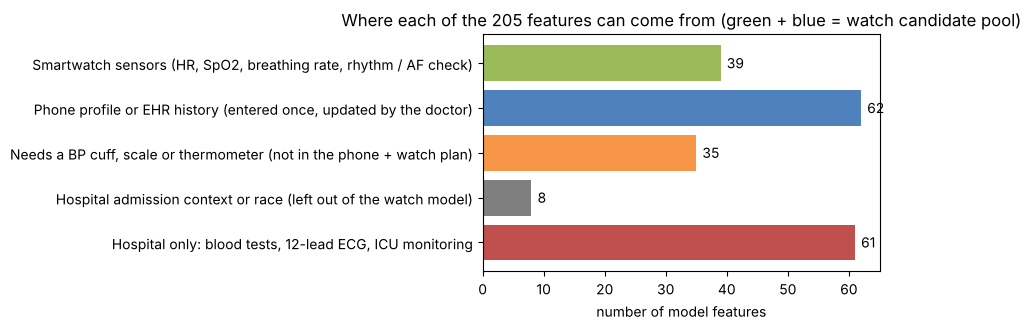

In [5]:
SRC_ORDER = ["watch", "phone_profile", "home_device", "hospital_context", "hospital_only"]
avail = pd.DataFrame({"feature": FEATURES, "source": [cml.feature_source(f) for f in FEATURES]})
avail["source_description"] = avail.source.map(cml.SOURCE_LABEL)
avail["missing_%_train"] = tr[FEATURES].isna().mean().mul(100).round(1).values
WATCH_FEATURES = [f for f in FEATURES if cml.feature_source(f) in ("watch", "phone_profile")]
avail["in_full_model"] = 1
avail["in_watch_model"] = avail.feature.isin(WATCH_FEATURES).astype(int)
avail.to_csv(RESULTS / "feature_availability.csv", index=False)
FEATURE_SETS = {"full": FEATURES, "watch": WATCH_FEATURES}

cnt = avail.source.value_counts().reindex(SRC_ORDER)
print(cnt.to_string())
print(f"\nwatch candidate pool: {len(WATCH_FEATURES)} features = {cnt['watch']} watch + {cnt['phone_profile']} phone profile / EHR history")
for s in SRC_ORDER:
    print(f"\n{s.upper()} ({cnt[s]}): " + ", ".join(avail[avail.source == s].feature.head(14)) + (" ..." if cnt[s] > 14 else ""))

fig, ax = plt.subplots(figsize=(9, 3.4))
ax.barh([cml.SOURCE_LABEL[s] for s in SRC_ORDER][::-1], cnt.values[::-1],
        color=[GREEN, BLUE, ORANGE, GREY, RED][::-1])
for i, v in enumerate(cnt.values[::-1]):
    ax.text(v + 1, i, str(v), va="center")
ax.set_xlabel("number of model features"); ax.set_title("Where each of the 205 features can come from (green + blue = watch candidate pool)")
savefig("01_feature_availability")

**Result:**

| Source | Features |
|---|---|
| Watch | 39 |
| Phone profile / EHR history | 62 |
| Home device | 35 |
| Hospital context or race | 8 |
| Hospital only | 61 |

The **watch model** can only use watch + phone profile: **101 candidate features**. BP, labs and the 12-lead ECG are not available from a phone and watch. Saved `01_feature_availability.png`.

## 4 · Patient-level split

**What this cell does:** checks the patient split from notebook 02 (stratified by whether the patient has an event, seed 42). No patient is in both train and test, and no patient is in two folds. It then counts patients, stays, hours and events per partition.

seed 42; split from notebook 02: patients stratified by 'has an event', 5 folds inside train
negative:positive ratio in TRAIN = 22.4 (used for class weights)


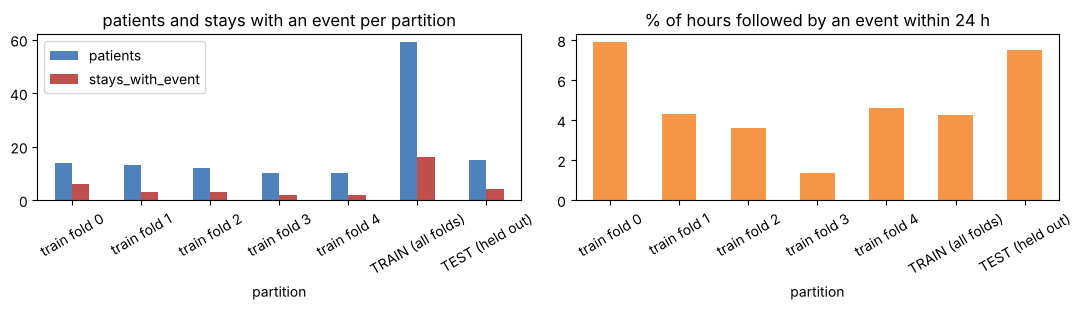

,partition,patients,icu_stays,hours,positive_hours,prevalence_%,stays_with_event,patient_days
0,train fold 0,14,17,621,49,7.89,6,25.9
1,train fold 1,13,17,882,38,4.31,3,36.8
2,train fold 2,12,19,744,27,3.63,3,31.0
3,train fold 3,10,12,666,9,1.35,2,27.8
4,train fold 4,10,13,478,22,4.60,2,19.9
5,TRAIN (all folds),59,78,3391,145,4.28,16,141.3
6,TEST (held out),15,19,1077,81,7.52,4,44.9


In [6]:
assert not set(df[tr_mask].subject_id) & set(df[te_mask].subject_id), "patient in both train and test"
assert df[tr_mask].groupby("subject_id").cv_fold.nunique().max() == 1, "patient in two folds"
def part_row(name, d):
    return {"partition": name, "patients": d.subject_id.nunique(), "icu_stays": d.stay_id.nunique(), "hours": len(d),
            "positive_hours": int(d.y.sum()), "prevalence_%": round(100 * d.y.mean(), 2),
            "stays_with_event": d[d.y == 1].stay_id.nunique(), "patient_days": round(len(d) / 24, 1)}
split_tab = pd.DataFrame([part_row(f"train fold {k}", df[tr_mask & (df.cv_fold == k)]) for k in range(5)]
                         + [part_row("TRAIN (all folds)", df[tr_mask]), part_row("TEST (held out)", df[te_mask])])
split_tab.to_csv(RESULTS / "split_summary.csv", index=False)

TR, TE = df[tr_mask].reset_index(drop=True), df[te_mask].reset_index(drop=True)
y_tr, y_te, folds = TR.y.values, TE.y.values, TR.cv_fold.values
RATIO = (y_tr == 0).sum() / y_tr.sum()
print(f"seed {SEED}; split from notebook 02: patients stratified by 'has an event', 5 folds inside train")
print(f"negative:positive ratio in TRAIN = {RATIO:.1f} (used for class weights)")
fig, axes = plt.subplots(1, 2, figsize=(11, 3.2))
split_tab.set_index("partition")[["patients", "stays_with_event"]].plot.bar(ax=axes[0], color=[BLUE, RED], rot=30)
axes[0].set_title("patients and stays with an event per partition")
split_tab.set_index("partition")["prevalence_%"].plot.bar(ax=axes[1], color=ORANGE, rot=30)
axes[1].set_title(f"% of hours followed by an event within {HORIZON} h")
savefig("02_split_overview")
split_tab

**Result:**

| Partition | Patients | Hours | Event hours | Stays with an event |
|---|---|---|---|---|
| Train (5 folds) | 59 | 3,391 | 145 | 16 |
| Test | 15 | 1,077 | 81 | 4 |

The class ratio in train is 22 negatives per positive. **Four test stays with an event is very few**, so every test number has a wide confidence interval. Saved `02_split_overview.png` and `results/split_summary.csv`.

**Why no separate validation, calibration and threshold cohorts?** The training patients hold only 16 stays with an event (after the leak fix in section 2). Cutting them into 3 or 4 more groups would leave a handful of events per group. Instead, every model-selection, calibration and threshold decision uses **out-of-fold (OOF) predictions**: each training hour is predicted by a model that never saw that patient (5 patient-grouped folds). Calibration and thresholds are cross-fitted on those OOF predictions, so they are leakage-safe too. The 17 test patients are used once, in section 8.

## 5 · Model training: helpers

## 5 · Helpers: metrics, models, cross-validation

**What this cell does:** defines the shared tools:
- Metrics at a cut-off.
- **Alert counting:** an alert fires when risk ≥ cut-off, and the same patient is re-alerted at most every 4 h.
- Event-level sensitivity and lead time.
- One function per model type (class weights only, no SMOTE).
- `oof_predict`: every training hour is predicted by a model that never saw that patient.
- **Repeated splits (round 2):** the original 5 patient folds plus 4 reshuffled patient splits, and `sturdy()`, which scores a model on all 5 repeats.

In [7]:
def thr_for_sens(y, p, target=SENS_TARGET):
    # highest threshold whose sensitivity is still >= target
    prec, rec, thr = precision_recall_curve(y, p)
    ok = np.where(rec[:-1] >= target)[0]
    return float(thr[ok[-1]]) if len(ok) else float(np.min(p))

def at_threshold(y, p, t):
    pred = (np.asarray(p) >= t).astype(int)
    tn, fp, fn, tp = confusion_matrix(y, pred, labels=[0, 1]).ravel()
    sens, ppv, spec = tp / max(tp + fn, 1), tp / max(tp + fp, 1), tn / max(tn + fp, 1)
    return {"threshold": t, "sensitivity": sens, "ppv": ppv, "specificity": spec,
            "f1": 2 * sens * ppv / max(sens + ppv, 1e-9), "tp": int(tp), "fp": int(fp), "fn": int(fn), "tn": int(tn)}

def alert_flags(stay, hrs, on, snooze=SNOOZE_H):
    # an alert fires when the risk is at or above the cut-off and no alert fired in this stay in the last `snooze` hours
    out, last_stay, last = np.zeros(len(on), dtype=int), None, -1e18
    for i in range(len(on)):
        if stay[i] != last_stay:
            last_stay, last = stay[i], -1e18
        if on[i] and hrs[i] - last >= snooze:
            out[i], last = 1, hrs[i]
    return out

def alert_stats(d, p, t):
    # d: rows with stay_id, hour, y, hours_to_event (any order); p: risk; t: cut-off
    d = d[["stay_id", "hour", "y", "hours_to_event"]].assign(p=np.asarray(p)).sort_values(["stay_id", "hour"])
    d["on"] = (d.p >= t).astype(int)
    d["alert"] = alert_flags(d.stay_id.values, d.hour.values.astype("datetime64[h]").astype(np.int64), d.on.values)
    days = len(d) / 24
    pos = d[d.y == 1]
    first = pos[pos.on == 1].groupby("stay_id").hours_to_event.max()      # earliest flagged hour in the 24 h before
    n_events = pos.stay_id.nunique()
    al = d[d.alert == 1]
    return {**at_threshold(d.y.values, d.on.values, 0.5), "threshold": t,
            "alerts_per_patient_day": len(al) / days, "false_alerts_per_patient_day": (al.y == 0).sum() / days,
            "alert_ppv": (al.y == 1).mean() if len(al) else np.nan,
            "event_level_sensitivity": len(first) / n_events if n_events else np.nan,
            "events_caught": f"{len(first)}/{n_events}", "median_lead_time_h": float(first.median()) if len(first) else np.nan}

def spw_value(y, mode):
    r = (y == 0).sum() / max(y.sum(), 1)
    return {"none": 1.0, "sqrt": float(np.sqrt(r)), "full": float(r)}[mode]

def make_model(kind, params, y_fit):
    p = dict(params)
    if kind == "xgboost":
        spw = spw_value(y_fit, p.pop("spw_mode"))
        return xgb.XGBClassifier(**p, scale_pos_weight=spw, tree_method="hist", eval_metric="aucpr",
                                 random_state=SEED, n_jobs=2, verbosity=0)
    if kind == "lightgbm":
        spw = spw_value(y_fit, p.pop("spw_mode"))
        return lgb.LGBMClassifier(**p, scale_pos_weight=spw, subsample_freq=1, random_state=SEED, n_jobs=2, verbose=-1)
    if kind == "random_forest":
        return RandomForestClassifier(**p, n_estimators=300, class_weight="balanced_subsample", random_state=SEED, n_jobs=2)
    if kind == "logistic_regression":
        return Pipeline([("impute", SimpleImputer(strategy="median", add_indicator=True, keep_empty_features=True)),
                         ("scale", StandardScaler()),
                         ("lr", LogisticRegression(C=p["C"], class_weight=p["class_weight"], max_iter=3000))])
    raise ValueError(kind)

def oof_predict(kind, params, X, y, folds):
    # every training hour is predicted by a model fitted on the other 4 folds (other patients)
    oof = np.zeros(len(y))
    for k in np.unique(folds):
        fit, val = folds != k, folds == k
        m = make_model(kind, params, y[fit]).fit(X[fit], y[fit])
        oof[val] = m.predict_proba(X[val])[:, 1]
    return oof

LGB_FIXED = {"n_estimators": 300, "learning_rate": 0.05, "num_leaves": 15, "max_depth": -1, "min_child_samples": 20,
             "subsample": 0.8, "colsample_bytree": 0.8, "reg_alpha": 0.0, "reg_lambda": 1.0, "spw_mode": "full"}
from sklearn.model_selection import StratifiedGroupKFold
REPEAT_FOLDS = [folds]                       # repeat 0 = the original folds; the others reshuffle patients
for r in range(1, N_REPEATS):
    f = np.zeros(len(y_tr), dtype=int)
    for k, (_, va) in enumerate(StratifiedGroupKFold(5, shuffle=True, random_state=SEED + r).split(TR, y_tr, TR.subject_id)):
        f[va] = k
    REPEAT_FOLDS.append(f)

def sturdy(kind, params, X, y):
    # AUROC + AUPRC averaged over repeated patient splits, minus half their spread: rewards models that hold up on any split
    aucs, aps, oof0 = [], [], None
    for r, f in enumerate(REPEAT_FOLDS):
        o = oof_predict(kind, params, X, y, f) if kind != "news2" else X
        oof0 = o if r == 0 else oof0
        aucs.append(roc_auc_score(y, o)); aps.append(average_precision_score(y, o))
    tot = np.array(aucs) + np.array(aps)
    return {"AUROC": np.mean(aucs), "AUROC_sd": np.std(aucs), "AUPRC": np.mean(aps), "AUPRC_sd": np.std(aps),
            "score": tot.mean() - 0.5 * tot.std()}, oof0
print("prevalence in train (= AUPRC of a random model):", round(y_tr.mean(), 4))

prevalence in train (= AUPRC of a random model): 0.0428


**Result:** helpers ready. A random model would score AUPRC 0.043, the event rate in train.

## 6 · Feature selection (on train folds only)

**What this cell does (feature selection, train folds only):**
1. Drops features missing in more than 80% of rows.
2. Drops near-constant features.
3. From each pair with correlation above 0.95, keeps the plainer one.
4. Fits LightGBM on each fold's training patients and ranks by gain importance. **SHAP is not used yet, as you asked.**
5. Keeps features in the top 50 in at least 4 of 5 folds, clamped to 40-60.
6. Checks that cross-validated AUPRC did not drop.

FULL: 205 -> missing>80%: -8 -> near-constant: -2 -> correlated>0.95: -0 -> stable top: 40  | AUPRC all 0.0813 vs selected 0.1336 -> selected set kept (AUPRC within 0.01 or better)
   dropped as correlated:  


WATCH: 101 -> missing>80%: -0 -> near-constant: -1 -> correlated>0.95: -0 -> stable top: 46  | AUPRC all 0.0924 vs selected 0.108 -> selected set kept (AUPRC within 0.01 or better)
   dropped as correlated:  


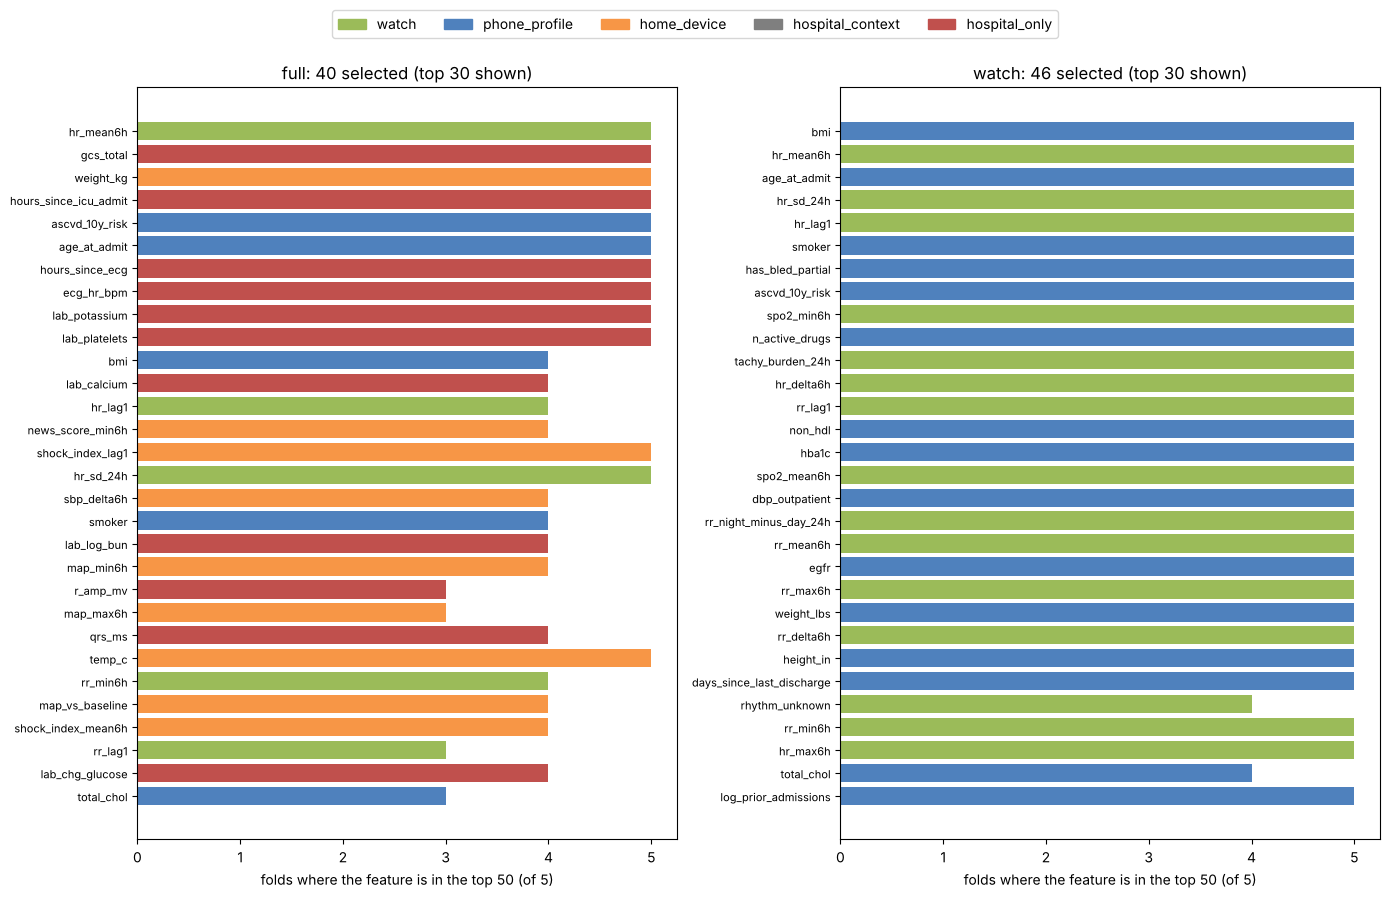

In [8]:
def simpler(a, b):
    # of two near-identical features keep the one a doctor reads more easily: the plain measurement, not the derived one
    rank = lambda f: (any(s in f for s in ("_lag1", "_mean6h", "_min6h", "_max6h", "_delta6h", "_vs_baseline", "_pct", "log_", "chg_")), len(f))
    return a if rank(a) <= rank(b) else b

def select_features(set_name, pool, n_top=50, min_folds=4, lo=40, hi=60):
    X = TR[pool].astype(float)
    log = {"start": len(pool)}
    miss = X.isna().mean()
    s1 = [f for f in pool if miss[f] <= 0.80]
    log["dropped_missing_>80%"] = sorted(set(pool) - set(s1))
    top_share = X[s1].apply(lambda c: c.value_counts(normalize=True).iloc[0] if c.notna().any() else 1.0)
    s2 = [f for f in s1 if top_share[f] < 0.995]
    log["dropped_near_constant"] = sorted(set(s1) - set(s2))
    C = X[s2].corr(min_periods=300).abs()
    drop = set()
    for i, a in enumerate(s2):
        for b in s2[i + 1:]:
            if a in drop or b in drop or not (C.loc[a, b] > 0.95):
                continue
            drop.add(b if simpler(a, b) == a else a)
    s3 = [f for f in s2 if f not in drop]
    log["dropped_correlated_>0.95"] = sorted(drop)
    ranks = pd.DataFrame(index=s3)
    for k in range(5):                      # importance from LightGBM fitted on the 4 training folds of each split
        fit = folds != k
        m = make_model("lightgbm", LGB_FIXED, y_tr[fit]).fit(X.loc[fit, s3], y_tr[fit])
        imp = pd.Series(m.booster_.feature_importance("gain"), index=s3)
        ranks[f"fold{k}"] = imp.rank(ascending=False)
    ranks["folds_in_top"] = (ranks[[f"fold{k}" for k in range(5)]] <= n_top).sum(axis=1)
    ranks["mean_rank"] = ranks[[f"fold{k}" for k in range(5)]].mean(axis=1)
    ranks = ranks.sort_values("mean_rank")
    stable = list(ranks[ranks.folds_in_top >= min_folds].index)
    if len(stable) < lo:
        stable = list(ranks.index[:lo])
    elif len(stable) > hi:
        stable = list(ranks.loc[stable].sort_values("mean_rank").index[:hi])
    log["kept_stable_top"] = len(stable)
    ranks["source"] = [cml.feature_source(f) for f in ranks.index]
    ranks["selected"] = ranks.index.isin(stable).astype(int)
    ranks.round(1).to_csv(RESULTS / f"feature_selection_{set_name}.csv")
    # confirm AUPRC did not drop: same fixed LightGBM, all features of the pool vs the selected set
    a_all = average_precision_score(y_tr, oof_predict("lightgbm", LGB_FIXED, X.values, y_tr, folds))
    a_sel = average_precision_score(y_tr, oof_predict("lightgbm", LGB_FIXED, X[stable].values, y_tr, folds))
    use = stable if a_sel >= a_all - 0.01 else s3
    log.update(auprc_all=round(a_all, 4), auprc_selected=round(a_sel, 4), final=len(use),
               decision="selected set kept (AUPRC within 0.01 or better)" if use is stable else "AUPRC dropped: kept all after step 3")
    return use, log, ranks

SELECTED, SEL_LOG, RANKS = {}, {}, {}
for s, pool in [("full", FEATURES), ("watch", WATCH_FEATURES)]:
    SELECTED[s], SEL_LOG[s], RANKS[s] = select_features(s, pool)
    lg = SEL_LOG[s]
    print(f"{s.upper()}: {lg['start']} -> missing>80%: -{len(lg['dropped_missing_>80%'])} -> near-constant: "
          f"-{len(lg['dropped_near_constant'])} -> correlated>0.95: -{len(lg['dropped_correlated_>0.95'])} -> "
          f"stable top: {lg['kept_stable_top']}  | AUPRC all {lg['auprc_all']} vs selected {lg['auprc_selected']} -> {lg['decision']}")
    print("   dropped as correlated:", ", ".join(lg["dropped_correlated_>0.95"][:12]), "..." if len(lg["dropped_correlated_>0.95"]) > 12 else "")
json.dump({s: {k: v for k, v in SEL_LOG[s].items()} | {"features": SELECTED[s]} for s in SELECTED},
          open(RESULTS / "feature_selection_log.json", "w"), indent=1)
FEATURE_SETS = SELECTED

fig, axes = plt.subplots(1, 2, figsize=(14, 9))
SRC_COL = {"watch": GREEN, "phone_profile": BLUE, "home_device": ORANGE, "hospital_context": GREY, "hospital_only": RED}
for ax, s in zip(axes, ["full", "watch"]):
    r = RANKS[s][RANKS[s].selected == 1].head(30)
    ax.barh(r.index[::-1], r.folds_in_top[::-1], color=[SRC_COL[c] for c in r.source[::-1]])
    ax.set(xlabel="folds where the feature is in the top 50 (of 5)", title=f"{s}: {len(SELECTED[s])} selected (top 30 shown)")
    ax.tick_params(axis="y", labelsize=8)
handles = [plt.Rectangle((0, 0), 1, 1, color=c) for c in SRC_COL.values()]
plt.tight_layout(rect=(0, 0, 1, 0.95))
fig.legend(handles, list(SRC_COL), loc="upper center", ncol=5, bbox_to_anchor=(0.5, 1.0))
plt.savefig(CHARTS / "03_feature_selection.png", dpi=110, bbox_inches="tight")
plt.show()

**Result:**
- **Full:** 205 → 40 features (8 dropped for missingness, 2 near-constant, none correlated above 0.95 because notebook 04 already removed duplicates). AUPRC rose from 0.081 to 0.134.
- **Watch:** 101 → 46 features. AUPRC rose from 0.092 to 0.108.

The smaller sets are kept. The full set leans on HR, GCS, weight, hours since ICU admission, ASCVD risk, age and labs. The watch set leans on BMI, 6 h HR, age, 24 h HR variability, smoking, bleeding-risk score, ASCVD and lowest SpO2. Saved `03_feature_selection.png` and `results/feature_selection_*.csv`.

## 7 · Train, tune and compare models

**What this cell does:** defines the **sturdy rule** used for tuning and for choosing models (round 2). Every candidate is scored on the original 5 patient folds **and 4 reshuffled patient splits**. The score is the mean of AUROC + AUPRC over these 5 repeats, minus half its spread, so a model that only shines on one split is penalised.
- **Optuna (TPE, seed 42)** tunes XGBoost and LightGBM on this score, with **small, regularised trees** only: XGBoost depth 2-4 and minimum child weight 5-50; LightGBM 3-15 leaves and at least 30 rows per leaf. Also searched: trees, learning rate, subsampling, regularisation, and `scale_pos_weight` (1, √ratio or the full ratio).
- **Early stopping:** the number of trees is tuned instead, because stopping on the fold that is then scored would leak.
- **Baselines:** logistic regression tries 4 C values × class_weight None/balanced. Random forest tries 2 large-leaf settings (20 or 50 rows per leaf). Both baselines are picked by the same sturdy score.

In [9]:
def tune(kind, X, y, n_trials):
    # deliberately small, regularised trees: 16 event stays cannot support deep models
    def objective(trial):
        p = {"n_estimators": trial.suggest_int("n_estimators", 50, 400, step=25),
             "learning_rate": trial.suggest_float("learning_rate", 0.01, 0.1, log=True),
             "colsample_bytree": trial.suggest_float("colsample_bytree", 0.4, 1.0),
             "subsample": trial.suggest_float("subsample", 0.6, 1.0),
             "reg_alpha": trial.suggest_float("reg_alpha", 1e-2, 10, log=True),
             "reg_lambda": trial.suggest_float("reg_lambda", 1, 50, log=True),
             "spw_mode": trial.suggest_categorical("spw_mode", ["none", "sqrt", "full"])}
        if kind == "xgboost":
            p.update(max_depth=trial.suggest_int("max_depth", 2, 4),
                     min_child_weight=trial.suggest_float("min_child_weight", 5, 50, log=True))
        else:
            p.update(num_leaves=trial.suggest_int("num_leaves", 3, 15), max_depth=-1,
                     min_child_samples=trial.suggest_int("min_child_samples", 30, 300, log=True))
        return sturdy(kind, p, X, y)[0]["score"]
    st = optuna.create_study(direction="maximize", sampler=optuna.samplers.TPESampler(seed=SEED))
    st.optimize(objective, n_trials=n_trials)
    best = dict(st.best_params)
    if kind == "lightgbm":
        best["max_depth"] = -1
    return best, st

def cv_row(name, m, oof0, secs, prob=True, note=""):
    t = thr_for_sens(y_tr, oof0)
    a = at_threshold(y_tr, oof0, t)
    return {"model": name, "AUPRC": m["AUPRC"], "AUPRC_sd": m["AUPRC_sd"], "AUROC": m["AUROC"], "AUROC_sd": m["AUROC_sd"],
            "sturdy_score": m["score"], "PPV @ 85% sensitivity": a["ppv"], "specificity @ 85% sensitivity": a["specificity"],
            "Brier (uncalibrated)": brier_score_loss(y_tr, oof0) if prob else np.nan, "train_seconds": round(secs, 1), "notes": note}

def grid(kind, options, X):
    best = None
    for p in options:
        m, o = sturdy(kind, p, X, y_tr)
        if best is None or m["score"] > best[0]["score"]:
            best = (m, o, p)
    return best

def run_feature_set(set_name, feats):
    X = TR[feats].astype(float).values
    res, oofs, params = [], {}, {}
    m, oofs["news2"] = sturdy("news2", None, TR.news_score.fillna(0).values.astype(float), y_tr)
    res.append(cv_row("NEWS2 score (baseline)", m, oofs["news2"], 0, prob=False,
                      note="no training; a score, not a probability; needs BP, temperature and consciousness"))
    t0 = time.time()
    m, oofs["logistic_regression"], params["logistic_regression"] = grid(
        "logistic_regression", [{"C": C, "class_weight": cw} for C in [0.001, 0.01, 0.1, 1.0] for cw in [None, "balanced"]], X)
    res.append(cv_row("Logistic regression (baseline)", m, oofs["logistic_regression"], time.time() - t0,
                      note=f"median imputation + missing flags, scaled; best {params['logistic_regression']}"))
    for kind, label, n in [("xgboost", "XGBoost (Optuna)", N_TRIALS_XGB), ("lightgbm", "LightGBM (Optuna)", N_TRIALS_LGBM)]:
        t0 = time.time()
        params[kind], st = tune(kind, X, y_tr, n)
        m, oofs[kind] = sturdy(kind, params[kind], X, y_tr)
        st.trials_dataframe().to_csv(RESULTS / f"optuna_trials_{kind}_{set_name}.csv", index=False)
        res.append(cv_row(label, m, oofs[kind], time.time() - t0,
                          note=f"{n} trials on the sturdy score; small trees; spw_mode={params[kind]['spw_mode']}"))
    t0 = time.time()
    m, oofs["random_forest"], params["random_forest"] = grid(
        "random_forest", [{"min_samples_leaf": leaf, "max_features": "sqrt"} for leaf in [20, 50]], X)
    res.append(cv_row("Random forest", m, oofs["random_forest"], time.time() - t0, note=f"small grid; best {params['random_forest']}"))
    tab = pd.DataFrame(res).set_index("model")
    tab.round(4).to_csv(RESULTS / f"model_comparison_cv_{set_name}.csv")
    return tab, oofs, params

**Result:** functions ready. Each model's comparison table is saved to `results/model_comparison_cv_*.csv`, and every Optuna trial to `results/optuna_trials_*.csv`.

**What this cell does:** trains and compares all models on the **full** feature set (40 selected features) with 5-fold patient cross-validation, repeated over 5 patient shuffles.

In [10]:
t0 = time.time()
cmp_full, oof_full, params_full = run_feature_set("full", FEATURE_SETS["full"])
print(f"FULL set ({len(FEATURE_SETS['full'])} features), done in {time.time() - t0:.0f} s; pooled out-of-fold results on {len(y_tr):,} train hours")
cmp_full.drop(columns="notes").round(3)

FULL set (40 features), done in 236 s; pooled out-of-fold results on 3,391 train hours


,AUPRC,AUPRC_sd,AUROC,AUROC_sd,sturdy_score,PPV @ 85% sensitivity,specificity @ 85% sensitivity,Brier (uncalibrated),train_seconds
model,,,,,,,,,
NEWS2 score (baseline),0.074,0.000,0.690,0.000,0.764,0.056,0.321,NaN,0.0
Logistic regression (baseline),0.202,0.036,0.789,0.021,0.964,0.074,0.520,0.091,4.6
XGBoost (Optuna),0.174,0.017,0.870,0.004,1.034,0.152,0.787,0.063,81.7
LightGBM (Optuna),0.179,0.016,0.871,0.009,1.038,0.148,0.781,0.042,88.4
Random forest,0.157,0.034,0.798,0.008,0.935,0.094,0.627,0.052,61.3


**Result (train patients; mean over 5 patient shuffles, ± SD):**

| Model | AUPRC | AUROC | Sturdy score |
|---|---|---|---|
| NEWS2 | 0.074 | 0.69 | 0.76 |
| Logistic regression | 0.202 ± 0.036 | 0.79 ± 0.02 | 0.96 |
| XGBoost | 0.174 ± 0.017 | 0.87 ± 0.004 | 1.034 |
| **LightGBM** | 0.179 ± 0.016 | **0.87 ± 0.009** | **1.038** |
| Random forest | 0.157 ± 0.034 | 0.80 ± 0.01 | 0.94 |

With smaller trees, LightGBM's AUPRC fell from 0.21 (round 1) to 0.18, but it is now steady across shuffles. The trees separate patients far better than NEWS2 (AUROC 0.87 vs 0.69).

**What this cell does:** the same comparison on the **watch** feature set (46 features from the watch and the phone profile).

In [11]:
t0 = time.time()
cmp_watch, oof_watch, params_watch = run_feature_set("watch", FEATURE_SETS["watch"])
print(f"WATCH set ({len(FEATURE_SETS['watch'])} features), done in {time.time() - t0:.0f} s")
cmp_watch.drop(columns="notes").round(3)

WATCH set (46 features), done in 215 s


,AUPRC,AUPRC_sd,AUROC,AUROC_sd,sturdy_score,PPV @ 85% sensitivity,specificity @ 85% sensitivity,Brier (uncalibrated),train_seconds
model,,,,,,,,,
NEWS2 score (baseline),0.074,0.000,0.690,0.000,0.764,0.056,0.321,NaN,0.0
Logistic regression (baseline),0.137,0.017,0.778,0.012,0.903,0.073,0.518,0.040,5.3
XGBoost (Optuna),0.128,0.033,0.772,0.029,0.870,0.067,0.472,0.044,68.2
LightGBM (Optuna),0.158,0.014,0.765,0.044,0.895,0.076,0.538,0.042,81.2
Random forest,0.146,0.017,0.780,0.014,0.912,0.068,0.472,0.053,60.2


**Result (mean over 5 patient shuffles, ± SD):**

| Model | AUPRC | AUROC | Sturdy score |
|---|---|---|---|
| NEWS2 (needs BP) | 0.074 | 0.69 | 0.76 |
| **Logistic regression** | 0.137 ± 0.017 | **0.78 ± 0.01** | 0.904 |
| XGBoost | 0.128 ± 0.033 | 0.77 ± 0.03 | 0.870 |
| LightGBM | 0.158 ± 0.014 | 0.77 ± 0.04 | 0.895 |
| Random forest | 0.146 ± 0.017 | 0.78 ± 0.01 | 0.912 |

Round 1's watch LightGBM AUPRC of 0.315 has gone: with small trees and reshuffled patients it is 0.16, and its AUROC swings the most. All four models score about the same.

**What this cell does:** picks the model for each feature set with the **sturdy rule**: the highest sturdy score, and when models are within 0.01 of the best, the **simpler** one wins (logistic regression, then random forest, LightGBM, XGBoost). In round 1 the rule was AUPRC alone, which picked an overfitted watch model. It also plots the comparison and the out-of-fold PR and ROC curves.

chosen by the sturdy rule (AUROC + AUPRC over repeated patient splits; simpler model wins ties): {'full': 'LightGBM (Optuna)', 'watch': 'Logistic regression (baseline)'}


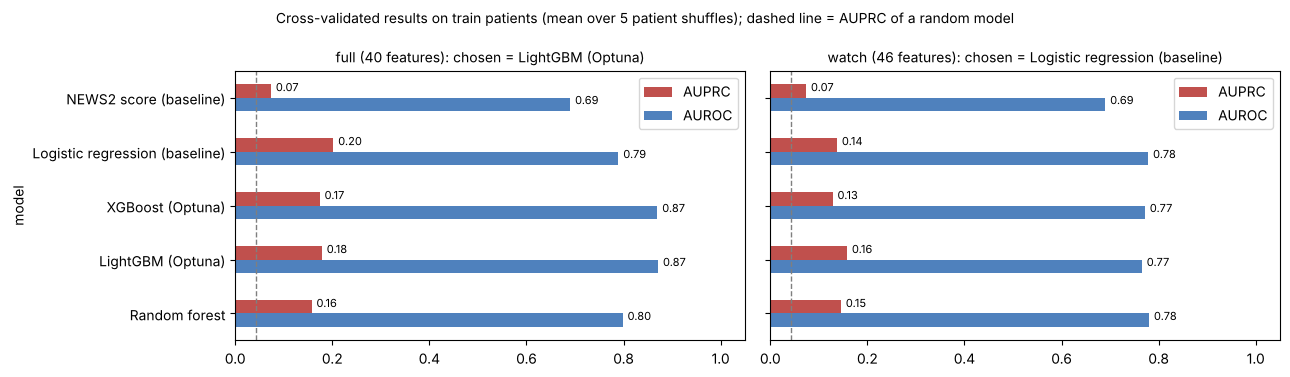

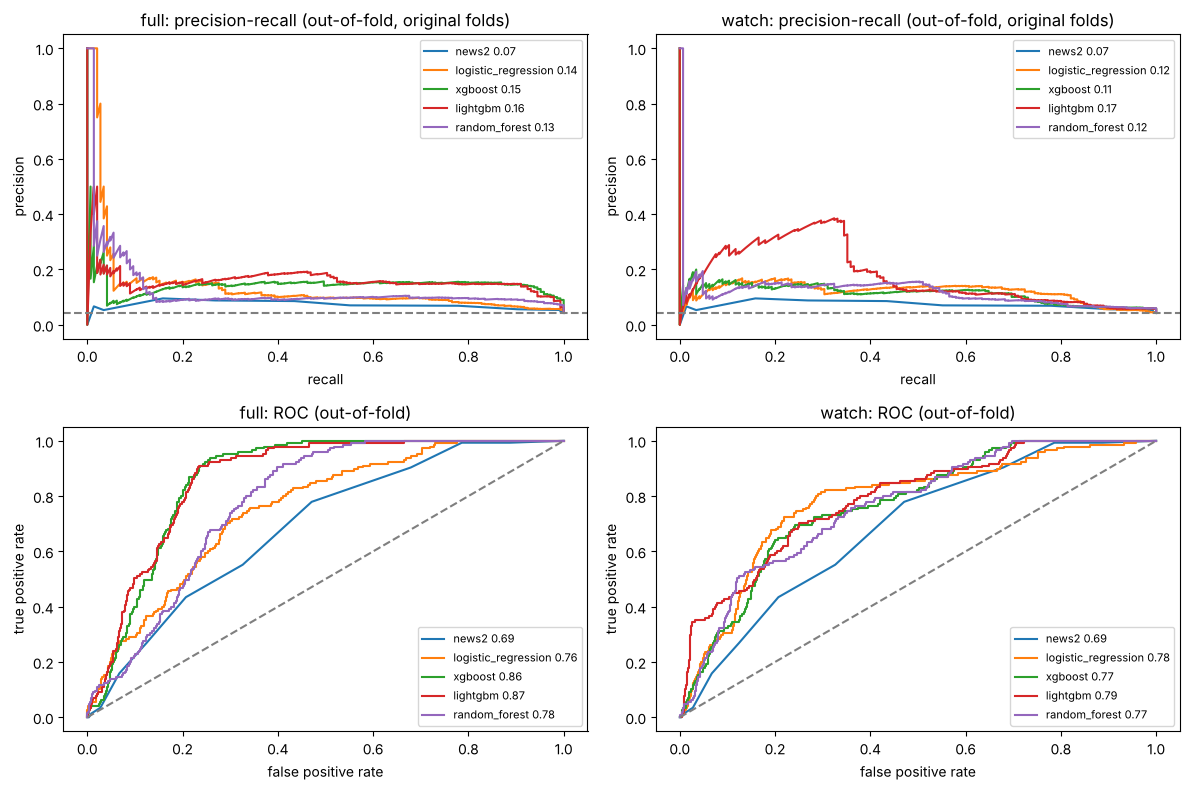

In [12]:
KIND = {"Logistic regression (baseline)": "logistic_regression", "XGBoost (Optuna)": "xgboost",
        "LightGBM (Optuna)": "lightgbm", "Random forest": "random_forest"}

SIMPLER = ["Logistic regression (baseline)", "Random forest", "LightGBM (Optuna)", "XGBoost (Optuna)"]

def choose(tab):
    # sturdy rule: highest (AUROC + AUPRC) over repeated patient splits minus half its spread;
    # within 0.01 of the best, the simpler model wins
    t = tab[tab.index.isin(KIND)]
    close = t[t.sturdy_score >= t.sturdy_score.max() - 0.01].index
    return next(m for m in SIMPLER if m in close)

SEL = {"full": choose(cmp_full), "watch": choose(cmp_watch)}
OOF = {"full": oof_full, "watch": oof_watch}
PARAMS = {"full": params_full, "watch": params_watch}
TABS = {"full": cmp_full, "watch": cmp_watch}
print("chosen by the sturdy rule (AUROC + AUPRC over repeated patient splits; simpler model wins ties):", SEL)

fig, axes = plt.subplots(1, 2, figsize=(13, 3.8), sharey=True)
for ax, (s, tab) in zip(axes, TABS.items()):
    t = tab[["AUPRC", "AUROC"]]
    t.plot.barh(ax=ax, color=[RED, BLUE])
    ax.axvline(y_tr.mean(), color=GREY, ls="--", lw=1)
    for i, (a, b) in enumerate(t.values):
        ax.text(a + .01, i - .12, f"{a:.2f}", fontsize=8); ax.text(b + .01, i + .12, f"{b:.2f}", fontsize=8)
    ax.set_xlim(0, 1.05); ax.set_title(f"{s} ({len(FEATURE_SETS[s])} features): chosen = {SEL[s]}", fontsize=10)
    ax.invert_yaxis()
fig.suptitle(f"Cross-validated results on train patients (mean over {N_REPEATS} patient shuffles); dashed line = AUPRC of a random model", fontsize=10)
savefig("04_model_comparison_cv")

fig, axes = plt.subplots(2, 2, figsize=(12, 8))
for j, s in enumerate(["full", "watch"]):
    for name, o in OOF[s].items():
        pr, rc, _ = precision_recall_curve(y_tr, o); fpr, tpr, _ = roc_curve(y_tr, o)
        axes[0, j].plot(rc, pr, label=f"{name} {average_precision_score(y_tr, o):.2f}")
        axes[1, j].plot(fpr, tpr, label=f"{name} {roc_auc_score(y_tr, o):.2f}")
    axes[0, j].axhline(y_tr.mean(), color=GREY, ls="--"); axes[1, j].plot([0, 1], [0, 1], color=GREY, ls="--")
    axes[0, j].set(xlabel="recall", ylabel="precision", title=f"{s}: precision-recall (out-of-fold, original folds)")
    axes[1, j].set(xlabel="false positive rate", ylabel="true positive rate", title=f"{s}: ROC (out-of-fold)")
    axes[0, j].legend(fontsize=8); axes[1, j].legend(fontsize=8)
savefig("05_pr_roc_cv")

**Result:**
- **Full:** **LightGBM** (sturdy score 1.038). XGBoost is within 0.01 (1.034), but LightGBM counts as the simpler of the two.
- **Watch:** **logistic regression.** Random forest scores highest (0.912), but logistic regression is within 0.01 (0.904) and simpler, so it wins.

Saved `04_model_comparison_cv.png` and `05_pr_roc_cv.png`.

## 8 · Probability calibration (cross-fitted on out-of-fold predictions)

**What this cell does:** compares no calibration, sigmoid (Platt) and isotonic calibration. Each is fitted on 4 folds of out-of-fold predictions and scored on the 5th, so nothing is fitted and scored on the same patients. The table is kept for information, but **sigmoid is now always used**: it is smooth and has only 2 parameters, while isotonic's steps made the High cut-off unreliable in round 1. It is refitted on all out-of-fold predictions. The same is done for the logistic regression baseline.

full: LightGBM (Optuna) -> sigmoid; logistic regression -> sigmoid
watch: Logistic regression (baseline) -> none; logistic regression -> none


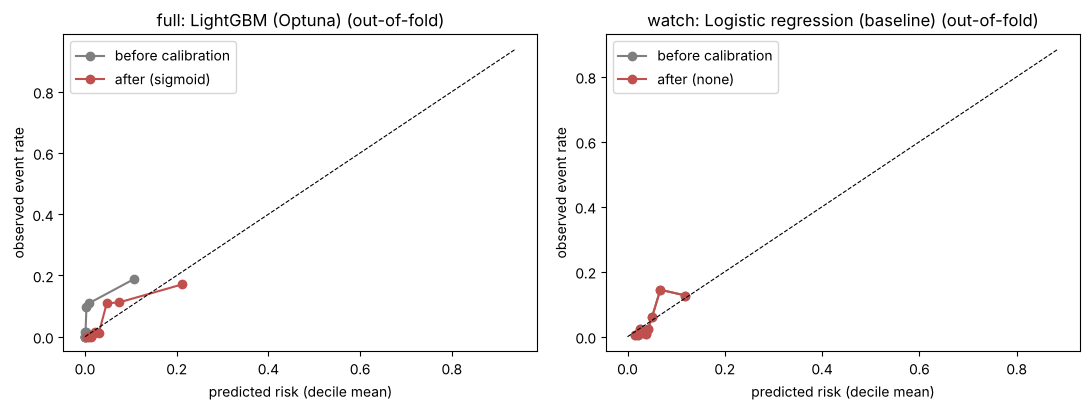

,feature_set,model,method,Brier,log_loss,mean_predicted,observed_rate,slope,intercept
0,full,LightGBM (Optuna),none,0.0420,0.2005,0.0121,0.0428,0.4900,1.8906
1,full,LightGBM (Optuna),sigmoid,0.0401,0.1486,0.0437,0.0428,0.9033,-0.0254
2,full,LightGBM (Optuna),isotonic,0.0393,0.1569,0.0436,0.0428,0.4369,-0.0248
0,full,Logistic regression (baseline),none,0.0907,0.3019,0.1534,0.0428,0.3777,-2.3190
1,full,Logistic regression (baseline),sigmoid,0.0399,0.1671,0.0439,0.0428,0.7823,-0.0290
2,full,Logistic regression (baseline),isotonic,0.0399,0.2352,0.0434,0.0428,0.0957,-0.0171
0,watch,Logistic regression (baseline),none,0.0398,0.1610,0.0445,0.0428,1.3397,-0.0420
1,watch,Logistic regression (baseline),sigmoid,0.0447,0.1790,0.0518,0.0428,0.4872,-0.2281
2,watch,Logistic regression (baseline),isotonic,0.0448,0.2252,0.0533,0.0428,0.0798,-0.2636


In [13]:
def cal_slope_intercept(y, p):
    p = np.clip(p, 1e-6, 1 - 1e-6)
    lp = np.log(p / (1 - p))
    slope = LogisticRegression(C=1e6, max_iter=1000).fit(lp.reshape(-1, 1), y).coef_[0][0]
    lo, hi = -10, 10                      # calibration-in-the-large: offset a with mean(sigmoid(a + lp)) = mean(y)
    for _ in range(60):
        a = (lo + hi) / 2
        lo, hi = (a, hi) if (1 / (1 + np.exp(-(a + lp)))).mean() < y.mean() else (lo, a)
    return float(slope), float(a)

def calibrate(raw):
    # compare none / sigmoid / isotonic, each fitted on 4 folds and scored on the 5th; isotonic is shown for information only
    rows, cross = [], {}
    for method in ["none", "sigmoid", "isotonic"]:
        cf = np.zeros_like(raw)
        for k in range(5):
            cf[folds == k] = cml.Calibrator(method).fit(raw[folds != k], y_tr[folds != k]).transform(raw[folds == k])
        sl, it = cal_slope_intercept(y_tr, cf)
        rows.append({"method": method, "Brier": brier_score_loss(y_tr, cf), "log_loss": log_loss(y_tr, np.clip(cf, 1e-6, 1 - 1e-6)),
                     "mean_predicted": cf.mean(), "observed_rate": y_tr.mean(), "slope": sl, "intercept": it})
        cross[method] = cf
    t = pd.DataFrame(rows)
    # smooth methods only (isotonic's steps broke the High cut-off in round 1): sigmoid, unless the raw risk is already better
    best = t[t.method.isin(["none", "sigmoid"])].sort_values("Brier").iloc[0].method
    return cml.Calibrator(best).fit(raw, y_tr), cross[best], t

CAL, OOF_CAL, CAL_TAB = {}, {}, []
LR_CAL, LR_OOF_CAL = {}, {}
for s in ["full", "watch"]:
    CAL[s], OOF_CAL[s], t = calibrate(OOF[s][KIND[SEL[s]]])
    CAL_TAB.append(t.assign(feature_set=s, model=SEL[s]))
    LR_CAL[s], LR_OOF_CAL[s], t = calibrate(OOF[s]["logistic_regression"])
    if SEL[s] != "Logistic regression (baseline)":
        CAL_TAB.append(t.assign(feature_set=s, model="Logistic regression (baseline)"))
    print(f"{s}: {SEL[s]} -> {CAL[s].method}; logistic regression -> {LR_CAL[s].method}")
cal_tab = pd.concat(CAL_TAB)[["feature_set", "model", "method", "Brier", "log_loss", "mean_predicted", "observed_rate", "slope", "intercept"]]
cal_tab.round(4).to_csv(RESULTS / "calibration_selection.csv", index=False)

fig, axes = plt.subplots(1, 2, figsize=(11, 4.2))
for ax, s in zip(axes, ["full", "watch"]):
    raw = OOF[s][KIND[SEL[s]]]
    for p, lbl, c in [(raw, "before calibration", GREY), (OOF_CAL[s], f"after ({CAL[s].method})", RED)]:
        q = pd.qcut(p, 10, duplicates="drop")
        g = pd.DataFrame({"p": p, "y": y_tr}).groupby(q, observed=True).mean()
        ax.plot(g.p, g.y, "o-", color=c, label=lbl)
    m = max(OOF_CAL[s].max(), raw.max()) * 1.05
    ax.plot([0, m], [0, m], "--", color="k", lw=.8)
    ax.set(xlabel="predicted risk (decile mean)", ylabel="observed event rate", title=f"{s}: {SEL[s]} (out-of-fold)")
    ax.legend()
savefig("06_calibration_before_after")
cal_tab.round(4)

**Result:**
- **Full LightGBM:** raw risks were far too low (mean 1.2% vs 4.3% observed). Sigmoid fixes the mean (4.4%), lowers the Brier score from 0.042 to 0.040, and brings the slope to 0.90, where 1 is perfect. Isotonic has a slightly lower Brier score, but a slope of only 0.44 and step-shaped risks, so it is not used.
- **Watch logistic regression:** already well calibrated (mean 4.5%, Brier 0.040), and sigmoid made it worse (0.045), so **no calibration** is applied.

Saved `06_calibration_before_after.png` and `results/calibration_selection.csv`.

**What this cell does:** checks calibration and AUROC by sex and age band on the out-of-fold predictions.

In [14]:
# calibration by subgroup (out-of-fold, train patients)
sub = []
for s in ["full", "watch"]:
    for name, m in [("male", TR.gender_male == 1), ("female", TR.gender_male == 0),
                    ("age < 65", TR.age_at_admit < 65), ("age >= 65", TR.age_at_admit >= 65)]:
        m = m.values
        sub.append({"feature_set": s, "subgroup": name, "patients": TR[m].subject_id.nunique(), "hours": int(m.sum()),
                    "event_stays": TR[m & (y_tr == 1)].stay_id.nunique(), "mean_predicted_%": round(100 * OOF_CAL[s][m].mean(), 2),
                    "observed_%": round(100 * y_tr[m].mean(), 2),
                    "AUROC": round(roc_auc_score(y_tr[m], OOF_CAL[s][m]), 3) if y_tr[m].sum() >= 5 else np.nan})
sub = pd.DataFrame(sub)
sub.to_csv(RESULTS / "calibration_by_subgroup_cv.csv", index=False)
sub

,feature_set,subgroup,patients,hours,event_stays,mean_predicted_%,observed_%,AUROC
0,full,male,29,1167,10,6.79,9.34,0.782
1,full,female,30,2224,6,3.10,1.62,0.873
2,full,age < 65,34,2099,7,4.45,3.57,0.841
3,full,age >= 65,25,1292,9,4.23,5.42,0.874
4,watch,male,29,1167,10,5.11,9.34,0.856
5,watch,female,30,2224,6,4.10,1.62,0.571
6,watch,age < 65,34,2099,7,4.22,3.57,0.859
7,watch,age >= 65,25,1292,9,4.81,5.42,0.687


**Result:** both models under-predict for men (6.8% and 5.1% predicted vs 9.3% observed) and over-predict for women (3.1% and 4.1% vs 1.6%). The full model separates well in every group (AUROC 0.78-0.87). The watch model is weaker for women (0.57) and patients 65+ (0.69), but no longer fails outright as in round 1 (0.28 and 0.38). Saved `results/calibration_by_subgroup_cv.csv`.

## 9 · Operating points (chosen on cross-validated predictions, never on test)

These are only used to **evaluate** the models. The alert engine itself comes later.

| Tier | Rule |
|---|---|
| **High** | The lowest risk cut-off that gives at most **1 alert per patient-day** on train patients. Its sensitivity is reported. |
| **Moderate** | The highest cut-off that still catches **85%** of event hours. It has higher sensitivity and more alerts, so it only triggers a check-in. |

An *alert* fires when the risk is at or above the cut-off. While it stays there, the same patient is re-alerted at most **every 4 hours** (snooze), so a risk that stays high still counts as alarm burden.

**What this cell does:** picks two operating points on cross-validated predictions:
- **High:** the lowest cut-off with at most 1 alert per patient-day.
- **Moderate:** the highest cut-off with 85% sensitivity.

It prints sensitivity, PPV, alert burden, how many event stays are caught, and lead time.


full (LightGBM (Optuna)): MODERATE >= 0.0472, HIGH >= 0.0891   (logistic regression: {'moderate': 0.0179, 'high': 0.0814})
          threshold  sensitivity    ppv  specificity  alerts_per_patient_day  false_alerts_per_patient_day  event_level_sensitivity events_caught  median_lead_time_h
MODERATE      0.047        0.855  0.145        0.775                   1.918                         1.642                    0.938         15/16               4.167
HIGH          0.089        0.448  0.170        0.902                   0.998                         0.807                    0.875         14/16               3.667



watch (Logistic regression (baseline)): MODERATE >= 0.0362, HIGH >= 0.0759   (logistic regression: {'moderate': 0.0362, 'high': 0.0759})
          threshold  sensitivity    ppv  specificity  alerts_per_patient_day  false_alerts_per_patient_day  event_level_sensitivity events_caught  median_lead_time_h
MODERATE      0.036        0.855  0.073        0.518                   3.560                         3.284                    1.000         16/16               3.667
HIGH          0.076        0.303  0.115        0.896                   0.998                         0.856                    0.875         14/16               3.667


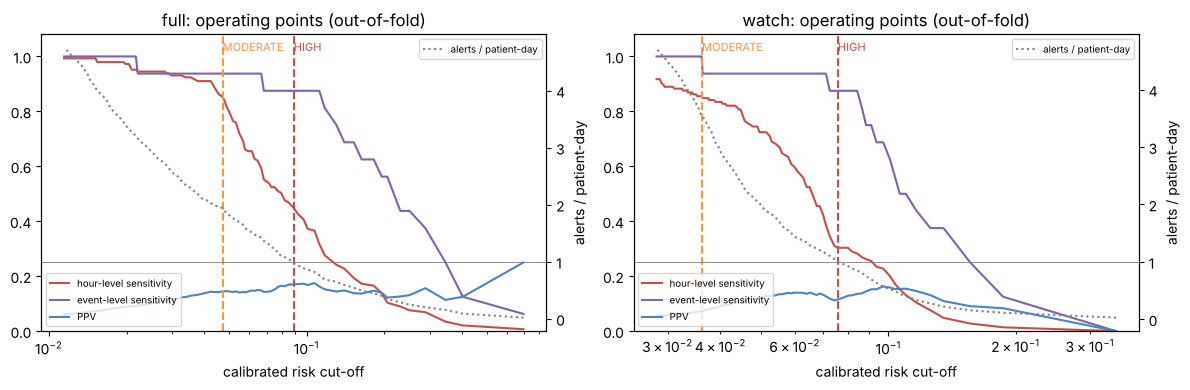

In [15]:
def operating_points(d, y, p):
    grid = np.unique(np.quantile(p, np.linspace(0.30, 0.999, 120)))
    tab = pd.DataFrame([alert_stats(d, p, t) for t in grid]).sort_values("threshold", ascending=False).reset_index(drop=True)
    over = np.where(tab.alerts_per_patient_day.values > MAX_ALERTS_PER_DAY)[0]     # walk down from the top cut-off
    high = float(tab.threshold.iloc[max(over[0] - 1, 0)] if len(over) else tab.threshold.iloc[-1])
    moderate = min(thr_for_sens(y, p, SENS_TARGET), high)
    return {"moderate": round(moderate, 4), "high": round(high, 4)}, tab

THR, THR_TAB, LR_THR = {}, {}, {}
for s in ["full", "watch"]:
    THR[s], THR_TAB[s] = operating_points(TR, y_tr, OOF_CAL[s])
    LR_THR[s], _ = operating_points(TR, y_tr, LR_OOF_CAL[s])
    THR_TAB[s].round(4).to_csv(RESULTS / f"operating_point_table_{s}.csv", index=False)
    print(f"\n{s} ({SEL[s]}): MODERATE >= {THR[s]['moderate']}, HIGH >= {THR[s]['high']}   (logistic regression: {LR_THR[s]})")
    print(pd.DataFrame([alert_stats(TR, OOF_CAL[s], THR[s][k]) for k in ("moderate", "high")], index=["MODERATE", "HIGH"])[
        ["threshold", "sensitivity", "ppv", "specificity", "alerts_per_patient_day", "false_alerts_per_patient_day",
         "event_level_sensitivity", "events_caught", "median_lead_time_h"]].round(3).to_string())
NEWS_THR = {"moderate": 5, "high": 7}           # standard NEWS2 trigger levels (urgent / emergency response)

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for ax, s in zip(axes, ["full", "watch"]):
    tt = THR_TAB[s]
    ax.plot(tt.threshold, tt.sensitivity, color=RED, label="hour-level sensitivity")
    ax.plot(tt.threshold, tt.event_level_sensitivity, color=PURPLE, label="event-level sensitivity")
    ax.plot(tt.threshold, tt.ppv, color=BLUE, label="PPV")
    ax2 = ax.twinx(); ax2.plot(tt.threshold, tt.alerts_per_patient_day, color=GREY, ls=":", label="alerts / patient-day")
    ax2.axhline(MAX_ALERTS_PER_DAY, color=GREY, lw=.6)
    for k, c in [("moderate", ORANGE), ("high", RED)]:
        ax.axvline(THR[s][k], color=c, ls="--"); ax.text(THR[s][k], 1.02, k.upper(), color=c, fontsize=8)
    ax.set(xlabel="calibrated risk cut-off", title=f"{s}: operating points (out-of-fold)", ylim=(0, 1.08), xscale="log")
    ax.legend(loc="lower left", fontsize=7); ax2.legend(loc="upper right", fontsize=7); ax2.set_ylabel("alerts / patient-day")
savefig("07_operating_points")

**Result (cross-validated, 16 training stays with an event):**

| Model | Level | Cut-off | Hour sensitivity | Alerts per patient-day | Events caught |
|---|---|---|---|---|---|
| Full | Moderate | ≥ 0.047 | 86% | 1.9 | 15/16 |
| Full | High | ≥ 0.089 | 45% | 1.0 | 14/16 |
| Watch | Moderate | ≥ 0.036 | 86% | 3.6 | 16/16 |
| Watch | High | ≥ 0.076 | 30% | 1.0 | 14/16 |

With smooth risks, both High cut-offs now catch 14 of 16 events at 1 alert per day (round 1: 12/16 and 4/16). NEWS2 uses its standard 5 and 7 triggers. Saved `07_operating_points.png`.

## 10 · Final models: refit on all train patients

**What this cell does:** refits every model with its tuned settings on **all** 59 train patients and saves each one to `models/candidates/`. The chosen models and the logistic regression baselines are kept for the test.

In [16]:
FINAL, LR_FINAL = {}, {}
for s in ["full", "watch"]:
    feats, kind = FEATURE_SETS[s], KIND[SEL[s]]
    Xtr = TR[feats].astype(float)
    for name, k in KIND.items():        # every candidate is refit and saved; the choice above is already fixed
        m = make_model(k, PARAMS[s][k], y_tr).fit(Xtr, y_tr)
        joblib.dump({"estimator": m, "features": feats, "params": PARAMS[s][k], "feature_set": s, "model": name,
                     "cv": TABS[s].loc[name, ["AUPRC", "AUROC"]].round(4).to_dict()}, MODELS / "candidates" / f"{s}_{k}.pkl")
        if k == kind:
            FINAL[s] = m
        if k == "logistic_regression":
            LR_FINAL[s] = m
print({s: type(m).__name__ for s, m in FINAL.items()})
print("saved:", sorted(p.name for p in (MODELS / "candidates").glob("*.pkl")))

{'full': 'LGBMClassifier', 'watch': 'Pipeline'}
saved: ['full_lightgbm.pkl', 'full_logistic_regression.pkl', 'full_random_forest.pkl', 'full_xgboost.pkl', 'watch_lightgbm.pkl', 'watch_logistic_regression.pkl', 'watch_random_forest.pkl', 'watch_xgboost.pkl']


**Result:** 8 candidate .pkl files saved (4 models × 2 feature sets).

## 11 · Test evaluation

**Note:** these 15 test patients were first scored in round 1. That round chose the watch model by AUPRC alone, and the model overfitted (test AUROC 0.61). This round changes the selection *rule* (sturdier, simpler models, smooth calibration only) without looking at which model wins on test. Still, the test set is now **seen once before**, so treat these results as a re-check, not a fully untouched estimate.

**What this cell does:** defines the test evaluation:
- AUPRC, AUROC and Brier score.
- Sensitivity and PPV at High and at Moderate.
- Alerts per patient-day.
- Event-level sensitivity and median lead time.

All come with **95% confidence intervals from 1,000 bootstrap resamples of patients** (a patient drawn twice counts as two patients).

In [17]:
def evaluate(d, p, thr, prob=True, n_boot=N_BOOT):
    y = d.y.values
    hi, mo = alert_stats(d, p, thr["high"]), alert_stats(d, p, thr["moderate"])
    out = {"AUPRC": average_precision_score(y, p), "AUROC": roc_auc_score(y, p), "Brier": brier_score_loss(y, p) if prob else np.nan,
           "sens_high": hi["sensitivity"], "ppv_high": hi["ppv"], "alerts_per_day_high": hi["alerts_per_patient_day"],
           "event_sens_high": hi["event_level_sensitivity"], "events_caught_high": hi["events_caught"],
           "median_lead_h_high": hi["median_lead_time_h"], "sens_moderate": mo["sensitivity"], "ppv_moderate": mo["ppv"],
           "alerts_per_day_moderate": mo["alerts_per_patient_day"], "event_sens_moderate": mo["event_level_sensitivity"]}
    pats = d.subject_id.unique()
    idx = {sid: np.where(d.subject_id.values == sid)[0] for sid in pats}
    rng, boots = np.random.default_rng(SEED), []
    keys = ["AUPRC", "AUROC", "Brier", "sens_high", "ppv_high", "alerts_per_day_high", "event_sens_high"]
    base = d[["subject_id", "stay_id", "hour", "y", "hours_to_event"]].reset_index(drop=True)
    for _ in range(n_boot):
        draws = rng.choice(pats, len(pats), replace=True)
        ii = np.concatenate([idx[s_] for s_ in draws])
        copy_id = np.concatenate([[j] * len(idx[s_]) for j, s_ in enumerate(draws)])
        db = base.iloc[ii].copy()
        db["stay_id"] = db.stay_id.astype(str) + "_" + copy_id.astype(str)     # a patient drawn twice counts as two patients
        yb, pb = y[ii], p[ii]
        if yb.sum() == 0 or yb.sum() == len(yb):
            continue
        h = alert_stats(db, pb, thr["high"])
        boots.append([average_precision_score(yb, pb), roc_auc_score(yb, pb), brier_score_loss(yb, pb) if prob else np.nan,
                      h["sensitivity"], h["ppv"], h["alerts_per_patient_day"], h["event_level_sensitivity"]])
    b = np.array(boots, dtype=float)
    for i, k in enumerate(keys):
        out[f"{k}_ci"] = (round(float(np.nanpercentile(b[:, i], 2.5)), 3), round(float(np.nanpercentile(b[:, i], 97.5)), 3)) \
            if np.isfinite(b[:, i]).any() else (np.nan, np.nan)
    out["bootstrap_resamples_used"] = len(b)
    return out
print("evaluation function ready")

evaluation function ready


**Result:** function ready.

**What this cell does:** **the test re-check.** These 15 patients were first scored in round 1, so they are no longer fully unseen. It scores them with the chosen models, next to the logistic regression and NEWS2 baselines, using the cut-offs fixed above.

In [18]:
TEST_P, ROWS = {}, []
for s in ["full", "watch"]:
    feats = FEATURE_SETS[s]
    TEST_P[s] = CAL[s].transform(FINAL[s].predict_proba(TE[feats].astype(float))[:, 1])
    TEST_P[f"{s}_lr"] = LR_CAL[s].transform(LR_FINAL[s].predict_proba(TE[feats].astype(float))[:, 1])
    ROWS.append({"feature_set": s, "model": f"{SEL[s]} (chosen)", **evaluate(TE, TEST_P[s], THR[s])})
    if SEL[s] != "Logistic regression (baseline)":          # when LR is the chosen model, do not list it twice
        ROWS.append({"feature_set": s, "model": "Logistic regression (baseline)", **evaluate(TE, TEST_P[f"{s}_lr"], LR_THR[s])})
TEST_P["news2"] = TE.news_score.fillna(0).values.astype(float)
ROWS.append({"feature_set": "hospital score", "model": "NEWS2 (>= 5 moderate, >= 7 high)", **evaluate(TE, TEST_P["news2"], NEWS_THR, prob=False)})
test_tab = pd.DataFrame(ROWS)
test_tab.to_csv(RESULTS / "test_results.csv", index=False)

def fmt(r, k, nd=2):
    v, c = r[k], r.get(f"{k}_ci", (np.nan, np.nan))
    return "-" if pd.isna(v) else f"{v:.{nd}f} ({c[0]:.{nd}f}-{c[1]:.{nd}f})"
show = pd.DataFrame({f"{r['feature_set']}: {r['model']}": {
    "AUPRC": fmt(r, "AUPRC"), "AUROC": fmt(r, "AUROC"), "Brier": fmt(r, "Brier", 3),
    "sensitivity @ HIGH": fmt(r, "sens_high"), "PPV @ HIGH": fmt(r, "ppv_high"),
    "alerts / patient-day @ HIGH": fmt(r, "alerts_per_day_high"), "event-level sensitivity @ HIGH": fmt(r, "event_sens_high"),
    "events caught @ HIGH": r["events_caught_high"], "median lead time (h) @ HIGH": "-" if pd.isna(r["median_lead_h_high"]) else round(r["median_lead_h_high"], 1),
    "sensitivity @ MODERATE": round(r["sens_moderate"], 2), "alerts / patient-day @ MODERATE": round(r["alerts_per_day_moderate"], 2)}
    for r in ROWS})
print(f"TEST: {TE.subject_id.nunique()} patients, {len(TE):,} hours, {int(y_te.sum())} event hours, "
      f"{TE[TE.y == 1].stay_id.nunique()} stays with an event, prevalence {y_te.mean():.3f}. 95% CI from {N_BOOT} patient bootstraps.")
show

TEST: 15 patients, 1,077 hours, 81 event hours, 4 stays with an event, prevalence 0.075. 95% CI from 1000 patient bootstraps.


,full: LightGBM (Optuna) (chosen),full: Logistic regression (baseline),watch: Logistic regression (baseline) (chosen),"hospital score: NEWS2 (>= 5 moderate, >= 7 high)"
AUPRC,0.19 (0.07-0.34),0.39 (0.03-0.75),0.19 (0.04-0.42),0.21 (0.04-0.46)
AUROC,0.80 (0.70-0.92),0.71 (0.16-0.97),0.73 (0.52-0.94),0.74 (0.58-0.91)
Brier,0.068 (0.022-0.120),0.066 (0.021-0.112),0.068 (0.023-0.117),-
sensitivity @ HIGH,0.32 (0.00-0.82),0.49 (0.00-0.78),0.33 (0.00-0.78),0.41 (0.12-0.74)
PPV @ HIGH,0.20 (0.00-0.31),0.36 (0.00-0.62),0.25 (0.00-0.47),0.24 (0.03-0.47)
alerts / patient-day @ HIGH,1.05 (0.40-1.80),0.89 (0.37-1.51),0.96 (0.54-1.73),1.40 (0.71-1.84)
event-level sensitivity @ HIGH,0.75 (0.00-1.00),0.75 (0.00-1.00),0.75 (0.00-1.00),1.00 (1.00-1.00)
events caught @ HIGH,3/4,3/4,3/4,4/4
median lead time (h) @ HIGH,23.0,23.0,23.0,17.5
sensitivity @ MODERATE,0.63,0.73,0.91,0.67


**Result (15 patients, 4 stays with an event; 95% CI from 1,000 patient bootstraps):**

| Model | AUROC (95% CI) | AUPRC | Events caught at High | Alerts per day at High | Median lead time |
|---|---|---|---|---|---|
| **Full LightGBM** | **0.80 (0.70-0.92)** | 0.19 | **3/4** | 1.05 | 23 h |
| Full logistic regression | 0.71 (0.16-0.97) | 0.39 | 3/4 | 0.89 | 23 h |
| **Watch logistic regression** | **0.73 (0.52-0.94)** | 0.19 | **3/4** | 0.96 | 23 h |
| NEWS2 | 0.74 (0.58-0.91) | 0.21 | 4/4 | 1.40 | 18 h |

**Honest reading:**
- **Both fixes worked.** The full model now catches 3 of 4 events at High (round 1: 1 of 4), and the watch model holds its cross-validated AUROC on test (0.78 to 0.73, where round 1 fell from 0.76 to 0.61).
- The watch model matches NEWS2 on AUROC and fires less often (0.96 vs 1.4 alerts a day), without needing a BP cuff or a nurse. NEWS2 still catches the 4th event.
- With only 4 test events, every interval is wide, and none of these differences is statistically certain.

**What this cell does:** saves the test metrics (`results/test_metrics.json`), every test prediction (`test_predictions.csv`) and the cross-validated predictions (`cv_oof_predictions.csv`). It then draws the test PR, ROC and calibration curves and the confusion matrices at Moderate and High.

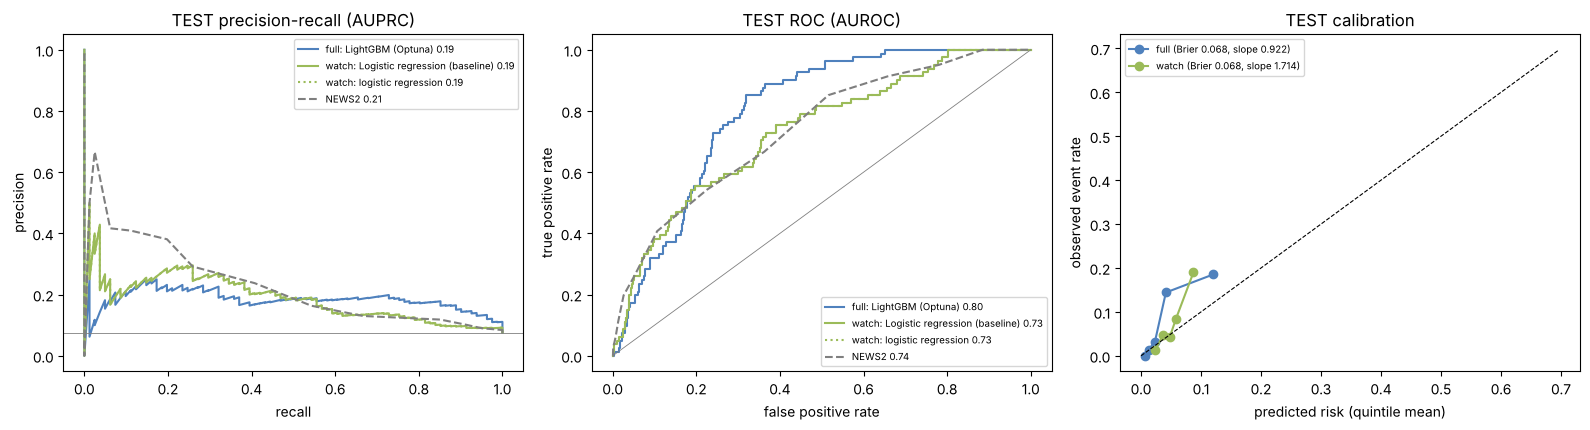

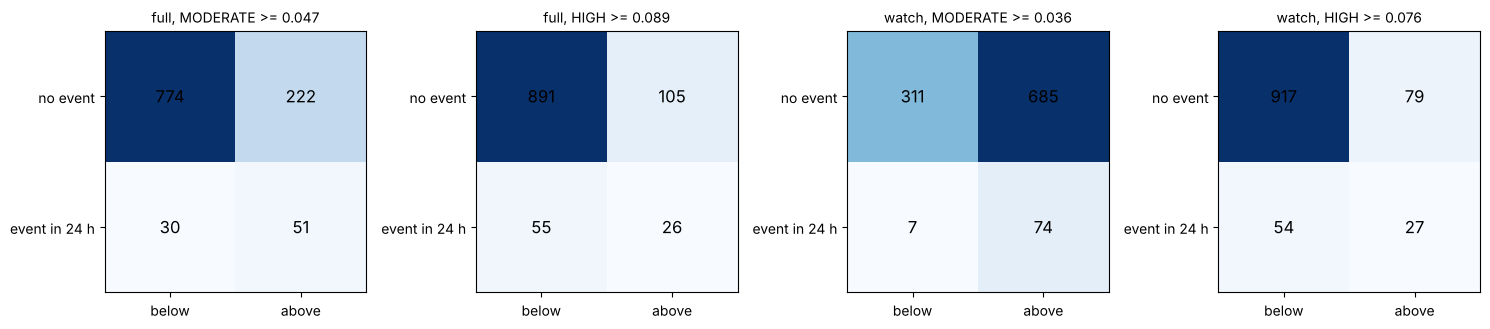

In [19]:
TEST_METRICS = {}
for s in ["full", "watch"]:
    p = TEST_P[s]
    sl, it = cal_slope_intercept(y_te, p)
    r = next(x for x in ROWS if x["feature_set"] == s and "chosen" in x["model"])
    TEST_METRICS[s] = {"model": SEL[s], "features": len(FEATURE_SETS[s]), "calibration": CAL[s].method, "operating_points": THR[s],
                       "test_patients": int(TE.subject_id.nunique()), "test_hours": int(len(TE)), "test_event_hours": int(y_te.sum()),
                       "test_event_stays": int(TE[TE.y == 1].stay_id.nunique()), "prevalence": round(float(y_te.mean()), 4),
                       "calibration_slope": round(sl, 3), "calibration_intercept": round(it, 3),
                       "mean_predicted": round(float(p.mean()), 4), **{k: (round(v, 4) if isinstance(v, float) else v) for k, v in r.items()
                                                                      if k not in ("feature_set", "model")}}
json.dump(TEST_METRICS, open(RESULTS / "test_metrics.json", "w"), indent=1, default=str)
pd.DataFrame({"subject_id": TE.subject_id, "stay_id": TE.stay_id, "hour": TE.hour, "y_24h": y_te, "hours_to_event": TE.hours_to_event.round(2),
              **{f"risk_{k}": np.round(v, 5) for k, v in TEST_P.items()}}).to_csv(RESULTS / "test_predictions.csv", index=False)
pd.DataFrame({"subject_id": TR.subject_id, "stay_id": TR.stay_id, "hour": TR.hour, "cv_fold": folds, "y_24h": y_tr,
              **{f"oof_risk_{s}": OOF_CAL[s].round(5) for s in OOF_CAL}}).to_csv(RESULTS / "cv_oof_predictions.csv", index=False)

fig, axes = plt.subplots(1, 3, figsize=(16, 4.4))
for key, lbl, c, ls in [("full", f"full: {SEL['full']}", BLUE, "-"), ("watch", f"watch: {SEL['watch']}", GREEN, "-"),
                        ("watch_lr", "watch: logistic regression", GREEN, ":"), ("news2", "NEWS2", GREY, "--")]:
    pr, rc, _ = precision_recall_curve(y_te, TEST_P[key]); fpr, tpr, _ = roc_curve(y_te, TEST_P[key])
    axes[0].plot(rc, pr, color=c, ls=ls, label=f"{lbl} {average_precision_score(y_te, TEST_P[key]):.2f}")
    axes[1].plot(fpr, tpr, color=c, ls=ls, label=f"{lbl} {roc_auc_score(y_te, TEST_P[key]):.2f}")
for key, c in [("full", BLUE), ("watch", GREEN)]:
    q = pd.qcut(TEST_P[key], 5, duplicates="drop")
    g = pd.DataFrame({"p": TEST_P[key], "y": y_te}).groupby(q, observed=True).mean()
    axes[2].plot(g.p, g.y, "o-", color=c, label=f"{key} (Brier {brier_score_loss(y_te, TEST_P[key]):.3f}, slope {TEST_METRICS[key]['calibration_slope']})")
mx = max(TEST_P["full"].max(), TEST_P["watch"].max())
axes[2].plot([0, mx], [0, mx], "--", color="k", lw=.8)
axes[0].axhline(y_te.mean(), color=GREY, lw=.6); axes[1].plot([0, 1], [0, 1], color=GREY, lw=.6)
axes[0].set(xlabel="recall", ylabel="precision", title="TEST precision-recall (AUPRC)")
axes[1].set(xlabel="false positive rate", ylabel="true positive rate", title="TEST ROC (AUROC)")
axes[2].set(xlabel="predicted risk (quintile mean)", ylabel="observed event rate", title="TEST calibration")
for a in axes:
    a.legend(fontsize=7)
savefig("08_test_pr_roc_calibration")

fig, axes = plt.subplots(1, 4, figsize=(15, 3.4))
for ax, (s, t) in zip(axes, [(s, t) for s in ["full", "watch"] for t in ["moderate", "high"]]):
    a = at_threshold(y_te, TEST_P[s], THR[s][t])
    cm = np.array([[a["tn"], a["fp"]], [a["fn"], a["tp"]]])
    ax.imshow(cm, cmap="Blues")
    for i in range(2):
        for j in range(2):
            ax.text(j, i, f"{cm[i, j]:,}", ha="center", va="center", fontsize=12)
    ax.set_xticks([0, 1], ["below", "above"]); ax.set_yticks([0, 1], ["no event", "event in 24 h"])
    ax.set_title(f"{s}, {t.upper()} >= {THR[s][t]:.3f}", fontsize=10)
savefig("09_test_confusion_matrices")

**Result:**
- **Calibration slopes:** 0.92 for the full model (close to the ideal 1) and 1.71 for the watch model, whose risks are too cautious at the extremes.
- **Mean predicted risk:** 4.1% (full) and 5.1% (watch). The test patients had more events (7.5%) than training (4.3%), so both under-predict on average.
- **Brier score:** 0.068 for both. Always predicting the 4.3% train rate would score about 0.070.

Saved `08_test_pr_roc_calibration.png` and `09_test_confusion_matrices.png`.

**What this cell does:** plots the hourly risk of both models for each of the 4 test stays with an event, with the event at hour 0.

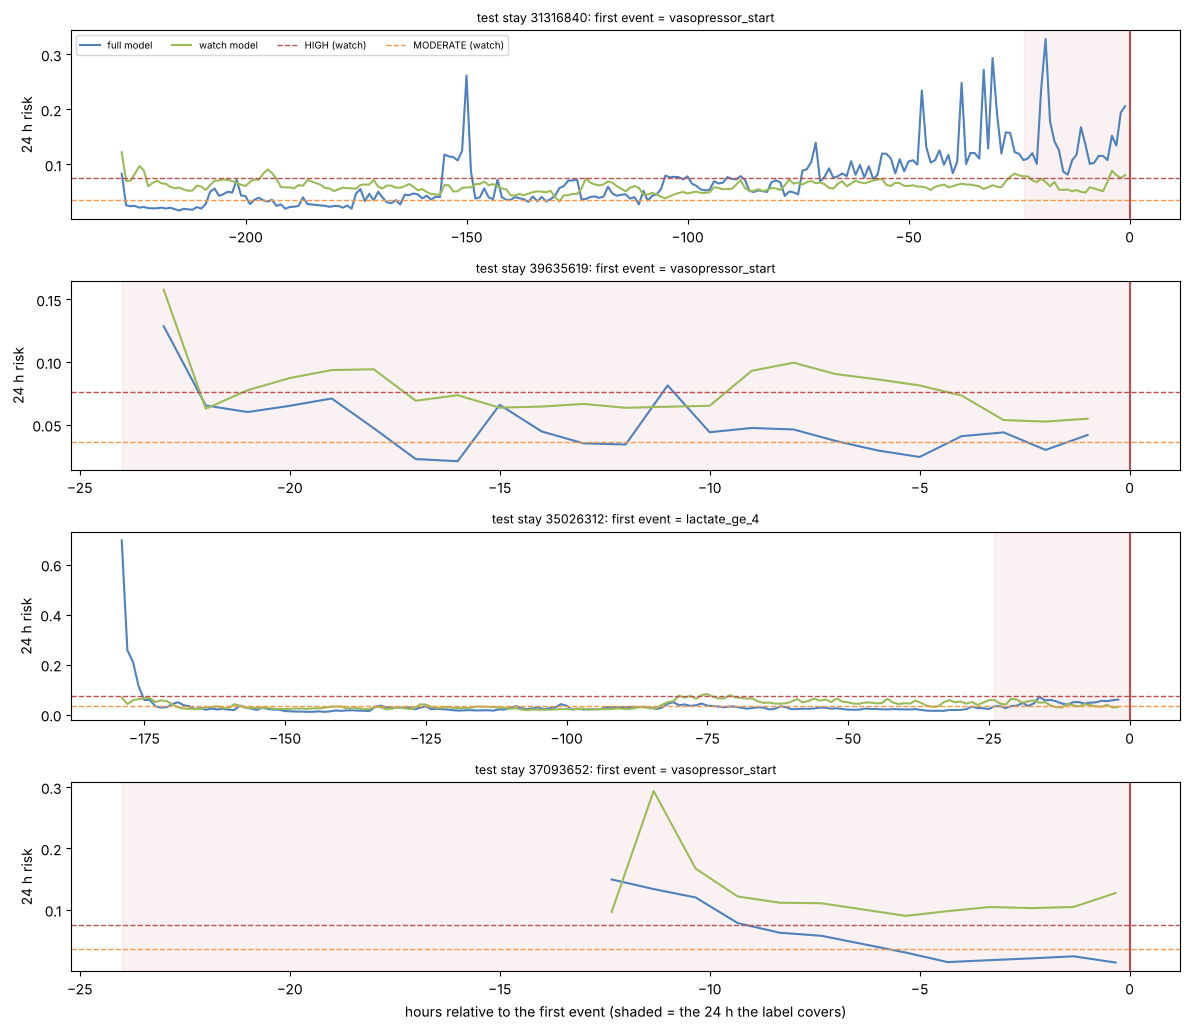

In [20]:
# every test stay with an event: risk over time for the chosen models
ev_stays = list(TE[TE.y == 1].groupby("stay_id").size().sort_values(ascending=False).index)
fig, axes = plt.subplots(len(ev_stays), 1, figsize=(12, 2.6 * len(ev_stays)), squeeze=False)
for ax, sid in zip(axes[:, 0], ev_stays):
    m = (TE.stay_id == sid).values
    d = TE[m]
    x = -d.hours_to_event
    ax.plot(x, TEST_P["full"][m], color=BLUE, label="full model"); ax.plot(x, TEST_P["watch"][m], color=GREEN, label="watch model")
    ax.axhline(THR["watch"]["high"], color=RED, ls="--", lw=1, label="HIGH (watch)")
    ax.axhline(THR["watch"]["moderate"], color=ORANGE, ls="--", lw=1, label="MODERATE (watch)")
    ax.axvspan(-24, 0, color=RED, alpha=.07); ax.axvline(0, color=RED)
    ax.set_title(f"test stay {sid}: first event = {d.first_event_type.iloc[0]}", fontsize=9)
    ax.set_ylabel("24 h risk")
axes[0, 0].legend(fontsize=7, ncol=4)
axes[-1, 0].set_xlabel("hours relative to the first event (shaded = the 24 h the label covers)")
savefig("10_test_patients_risk_timeline")

**Result:**
- **Stay 31316840:** the full model rises above the High line from about 70 h before the event and keeps spiking up to it.
- **Stays 37093652 and 39635619:** the watch model sits above High for most of the last day.
- **Stay 35026312** (the lactate event): neither model rises before the event.

The curves are now smooth instead of stepped. Saved `10_test_patients_risk_timeline.png`.

**What this cell does:** test results by sex and age band, with counts.

In [21]:
# subgroups on the test patients: sex and age band (counts shown because they are small)
sg = []
for name, m in [("male", TE.gender_male == 1), ("female", TE.gender_male == 0), ("age < 65", TE.age_at_admit < 65),
                ("age >= 65", TE.age_at_admit >= 65)]:
    m = m.values
    for s in ["full", "watch"]:
        d, p = TE[m], TEST_P[s][m]
        ok = 0 < d.y.sum() < len(d)
        h = alert_stats(d, p, THR[s]["high"])
        sg.append({"subgroup": name, "feature_set": s, "patients": d.subject_id.nunique(), "hours": len(d),
                   "event_stays": d[d.y == 1].stay_id.nunique(), "AUROC": round(roc_auc_score(d.y, p), 3) if ok else np.nan,
                   "AUPRC": round(average_precision_score(d.y, p), 3) if ok else np.nan,
                   "sens_high": round(h["sensitivity"], 3) if ok else np.nan, "alerts_per_day_high": round(h["alerts_per_patient_day"], 2),
                   "mean_predicted_%": round(100 * p.mean(), 2), "observed_%": round(100 * d.y.mean(), 2)})
sg = pd.DataFrame(sg)
sg.to_csv(RESULTS / "test_subgroups.csv", index=False)
sg

,subgroup,feature_set,patients,hours,event_stays,AUROC,AUPRC,sens_high,alerts_per_day_high,mean_predicted_%,observed_%
0,male,full,11,899,4,0.782,0.200,0.321,1.15,4.44,9.01
1,male,watch,11,899,4,0.715,0.213,0.333,0.99,5.26,9.01
2,female,full,4,178,0,NaN,NaN,NaN,0.54,2.26,0.00
3,female,watch,4,178,0,NaN,NaN,NaN,0.81,4.13,0.00
4,age < 65,full,6,499,2,0.906,0.347,0.022,0.24,2.44,9.02
5,age < 65,watch,6,499,2,0.783,0.313,0.222,0.53,4.05,9.02
6,age >= 65,full,9,578,2,0.805,0.204,0.694,1.74,5.50,6.23
7,age >= 65,watch,9,578,2,0.770,0.185,0.472,1.33,5.96,6.23


**Result:** all 4 test events are in men, and the 4 test women had none, so **no result can be given for women**. By age:
- **Full model:** AUROC 0.91 under 65 and 0.81 at 65+.
- **Watch model:** AUROC 0.78 under 65 and 0.77 at 65+.

Each age band has 2 events, far too few for fairness conclusions. Saved `results/test_subgroups.csv`.

## 12 · Prediction horizon: 6 h vs 12 h vs 24 h

**What this cell does:** retrains the chosen model type with the same settings for 6 h, 12 h and 24 h horizons, and compares cross-validated and test scores.

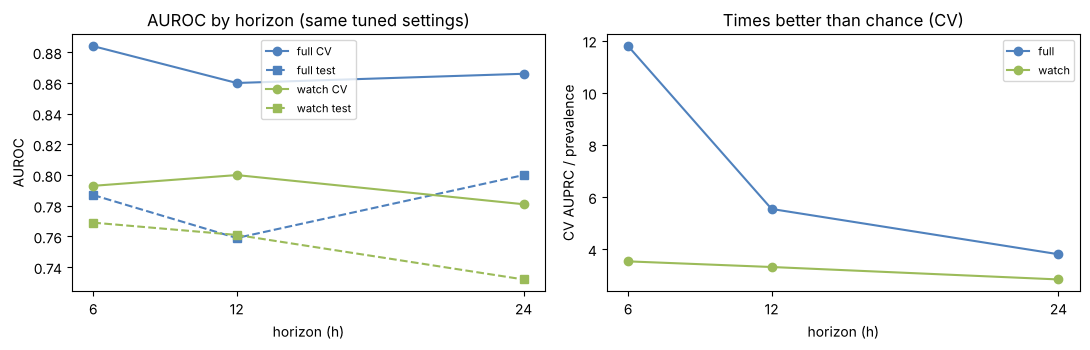

,feature_set,horizon_h,train_prevalence,cv_AUPRC,cv_AUROC,test_prevalence,test_AUPRC,test_AUROC,cv_AUPRC_x_chance
0,full,6,0.017,0.198,0.884,0.020,0.055,0.787,11.789
1,full,12,0.027,0.152,0.860,0.042,0.108,0.759,5.546
2,full,24,0.043,0.163,0.866,0.075,0.188,0.800,3.809
3,watch,6,0.017,0.059,0.793,0.020,0.069,0.769,3.536
4,watch,12,0.027,0.091,0.800,0.042,0.162,0.761,3.320
5,watch,24,0.043,0.122,0.781,0.075,0.193,0.732,2.843


In [22]:
hz = []
for s in ["full", "watch"]:
    feats, kind = FEATURE_SETS[s], KIND[SEL[s]]
    for H in (6, 12, 24):
        yh, yt = TR[f"y_{H}h"].values, TE[f"y_{H}h"].values
        o = oof_predict(kind, PARAMS[s][kind], TR[feats].astype(float).values, yh, folds)
        m = make_model(kind, PARAMS[s][kind], yh).fit(TR[feats].astype(float), yh)
        pt = m.predict_proba(TE[feats].astype(float))[:, 1]
        hz.append({"feature_set": s, "horizon_h": H, "train_prevalence": yh.mean(), "cv_AUPRC": average_precision_score(yh, o),
                   "cv_AUROC": roc_auc_score(yh, o), "test_prevalence": yt.mean(),
                   "test_AUPRC": average_precision_score(yt, pt), "test_AUROC": roc_auc_score(yt, pt)})
hz = pd.DataFrame(hz)
hz["cv_AUPRC_x_chance"] = hz.cv_AUPRC / hz.train_prevalence
hz = hz.round(3)
hz.to_csv(RESULTS / "horizon_comparison.csv", index=False)
fig, axes = plt.subplots(1, 2, figsize=(11, 3.6))
for s, c in [("full", BLUE), ("watch", GREEN)]:
    h = hz[hz.feature_set == s]
    axes[0].plot(h.horizon_h, h.cv_AUROC, "o-", color=c, label=f"{s} CV"); axes[0].plot(h.horizon_h, h.test_AUROC, "s--", color=c, label=f"{s} test")
    axes[1].plot(h.horizon_h, h.cv_AUPRC_x_chance, "o-", color=c, label=s)
axes[0].set(xlabel="horizon (h)", ylabel="AUROC", title="AUROC by horizon (same tuned settings)", xticks=[6, 12, 24]); axes[0].legend(fontsize=8)
axes[1].set(xlabel="horizon (h)", ylabel="CV AUPRC / prevalence", title="Times better than chance (CV)", xticks=[6, 12, 24]); axes[1].legend(fontsize=8)
savefig("11_horizon_comparison")
hz

**Result:**

| Horizon | Full: CV / test AUROC | Watch: CV / test AUROC |
|---|---|---|
| 6 h | 0.88 / 0.79 | 0.79 / 0.77 |
| 12 h | 0.86 / 0.76 | 0.80 / 0.76 |
| 24 h | 0.87 / 0.80 | 0.78 / 0.73 |

The horizons perform about the same. 24 h has the most event hours and the longest warning, so keeping it is reasonable. Saved `11_horizon_comparison.png`.

## 13 · Save models and results

**What this cell does:** saves each chosen model as **one .pkl bundle**. A bundle holds the model, its calibrator, the exact feature list and order, the operating points, the CV and test metrics, the library versions and the seed. It also saves:
- `selected_model.joblib` and `calibration_artifact.joblib` (watch)
- `feature_schema.json`
- `model_metadata.json`
- `operating_points.json`

It then reloads a bundle to check it reproduces the predictions.

In [23]:
BUNDLES = {}
for s in ["full", "watch"]:
    BUNDLES[s] = {
        "name": f"cardiotwin-{s}-{HORIZON}h", "version": f"1.0.0+{VERSION_DATE}", "feature_set": s, "horizon_h": HORIZON,
        "model_type": SEL[s], "params": PARAMS[s][KIND[SEL[s]]], "features": FEATURE_SETS[s], "estimator": FINAL[s],
        "calibrator": CAL[s], "operating_points": THR[s], "base_rate": round(float(y_tr.mean()), 4),
        "label_definition": f"first vasopressor start, lactate >= 4 or in-hospital death in (t, t+{HORIZON}h], t = end of the hour bin",
        "train_patients": int(TR.subject_id.nunique()), "train_hours": int(len(TR)), "train_event_hours": int(y_tr.sum()),
        "cv_metrics": TABS[s].loc[SEL[s], ["AUPRC", "AUROC"]].round(4).to_dict(), "test_metrics": TEST_METRICS[s],
        "feature_sources": {f: cml.feature_source(f) for f in FEATURE_SETS[s]}, "libraries": LIBS, "seed": SEED,
        "trained_at": datetime.now(timezone.utc).isoformat()}
    joblib.dump(BUNDLES[s], MODELS / f"cardiotwin_{s}_{HORIZON}h.pkl")
joblib.dump(FINAL["watch"], MODELS / "selected_model.joblib")
joblib.dump(CAL["watch"], MODELS / "calibration_artifact.joblib")
json.dump({s: {"features": [{"name": f, "position": i, "dtype": "float", "source": cml.feature_source(f),
                             "train_missing_%": round(float(TR[f].isna().mean() * 100), 1)} for i, f in enumerate(FEATURE_SETS[s])],
               "missing_values": "left as NaN; tree models handle them natively"} for s in FEATURE_SETS},
          open(MODELS / "feature_schema.json", "w"), indent=1)
meta = {s: {k: v for k, v in BUNDLES[s].items() if k not in ("estimator", "calibrator", "features", "feature_sources")}
        | {"calibration": CAL[s].method, "n_features": len(FEATURE_SETS[s]), "file": f"models/cardiotwin_{s}_{HORIZON}h.pkl"}
        for s in BUNDLES}
meta["model_for_phone_and_watch"] = "cardiotwin_watch_24h"
json.dump(meta, open(MODELS / "model_metadata.json", "w"), indent=1, default=str)
json.dump({s: {"operating_points": THR[s], "rule": f"HIGH = lowest cut-off with <= {MAX_ALERTS_PER_DAY:g} alert per patient-day (CV); "
               f"MODERATE = highest cut-off with >= {SENS_TARGET:.0%} sensitivity (CV). For evaluation; not clinically approved."}
           for s in THR}, open(MODELS / "operating_points.json", "w"), indent=1)

# reload check: the saved bundle gives exactly the same test predictions
re = joblib.load(MODELS / "cardiotwin_watch_24h.pkl")
p2 = re["calibrator"].transform(re["estimator"].predict_proba(TE[re["features"]].astype(float))[:, 1])
print("reloaded watch model reproduces the test predictions:", bool(np.allclose(p2, TEST_P["watch"])))
for p in sorted(MODELS.rglob("*")):
    if p.is_file():
        print(f"{str(p.relative_to(ROOT)):48s} {p.stat().st_size / 1024:8.1f} KB")

reloaded watch model reproduces the test predictions: True
models/calibration_artifact.joblib                    0.1 KB
models/candidates/full_lightgbm.pkl                 472.7 KB
models/candidates/full_logistic_regression.pkl        6.0 KB
models/candidates/full_random_forest.pkl            998.2 KB
models/candidates/full_xgboost.pkl                  331.4 KB
models/candidates/watch_lightgbm.pkl                338.5 KB
models/candidates/watch_logistic_regression.pkl       6.2 KB
models/candidates/watch_random_forest.pkl          1086.5 KB
models/candidates/watch_xgboost.pkl                 331.4 KB
models/cardiotwin_full_24h.pkl                      475.1 KB
models/cardiotwin_watch_24h.pkl                       8.0 KB
models/feature_schema.json                           11.5 KB
models/model_metadata.json                            4.5 KB
models/operating_points.json                          0.5 KB
models/selected_model.joblib                          5.5 KB


**Result:** the reloaded watch bundle reproduces the test predictions exactly. **To load a .pkl you need `cardiotwin_ml.py` in the same folder and the versions in `requirements_ml.txt`.**

**What this cell does:** writes `results/training_summary.json` and a readable report, `docs/MODEL_TRAINING_REPORT.md`, and lists every chart and result file.

In [24]:
w, f = TEST_METRICS["watch"], TEST_METRICS["full"]
summary = {"objective": BUNDLES["watch"]["label_definition"], "label_leak_fixed_hours": int(overlap.sum()),
           "split": split_tab.set_index("partition")[["patients", "hours", "positive_hours", "stays_with_event"]].to_dict("index"),
           "feature_selection": {s: {k: SEL_LOG[s][k] for k in ("start", "kept_stable_top", "auprc_all", "auprc_selected", "final")} for s in SEL_LOG},
           "chosen": SEL, "calibration": {s: CAL[s].method for s in CAL}, "operating_points": THR,
           "cv": {s: TABS[s][["AUPRC", "AUROC"]].round(3).to_dict("index") for s in TABS},
           "test": {r["feature_set"] + " | " + r["model"]: {k: r[k] for k in ("AUPRC", "AUPRC_ci", "AUROC", "AUROC_ci", "Brier", "sens_high",
                    "ppv_high", "alerts_per_day_high", "event_sens_high", "events_caught_high", "median_lead_h_high")} for r in ROWS}}
json.dump(summary, open(RESULTS / "training_summary.json", "w"), indent=1, default=str)

def tbl(d):
    d = d.reset_index()
    return "| " + " | ".join(map(str, d.columns)) + " |\n|" + "---|" * len(d.columns) + "\n" + \
           "\n".join("| " + " | ".join(map(str, r)) + " |" for r in d.values)

report = f"""# CardioTwin model training report (v{BUNDLES['watch']['version']})

Generated by `05_model_training.ipynb`. Research prototype, **not a medical device**.

## Objective
Probability of a **first deterioration event** (vasopressor start, lactate >= 4 mmol/L, or in-hospital death) in the next
**{HORIZON} hours**, made at the end of each hourly bin with data recorded up to then. This is a deterioration proxy, not a
heart-attack or cardiac-arrest prediction. {int(overlap.sum())} hours whose own 1-hour bin already contained the event were
removed (label leak in the earlier 6 h label).

## Data and split
MIMIC-IV demo, ICU patients only, so this is an **ICU-derived research prototype**. The watch model uses ICU monitor values of
signals a watch can measure (HR, SpO2, breathing rate, rhythm) plus the phone profile; no real watch data was available.

{tbl(split_tab.set_index('partition'))}

## Feature selection (train folds only)
Full: {SEL_LOG['full']['start']} -> {len(FEATURE_SETS['full'])} features; watch: {SEL_LOG['watch']['start']} -> {len(FEATURE_SETS['watch'])}.
Steps: missing > 80%, near-constant, correlation > 0.95, LightGBM gain importance in the top 50 in >= 4 of 5 folds.
Details: `results/feature_selection_*.csv`, `results/feature_selection_log.json`.

## Cross-validated comparison (5 patient folds, repeated over {N_REPEATS} patient shuffles; mean and SD)
Full:

{tbl(cmp_full[['AUPRC', 'AUPRC_sd', 'AUROC', 'AUROC_sd', 'sturdy_score', 'Brier (uncalibrated)']].round(3))}

Watch:

{tbl(cmp_watch[['AUPRC', 'AUPRC_sd', 'AUROC', 'AUROC_sd', 'sturdy_score', 'Brier (uncalibrated)']].round(3))}

Chosen: full = **{SEL['full']}**, watch = **{SEL['watch']}**. Calibration: full = {CAL['full'].method}, watch = {CAL['watch'].method}.
Imbalance: class weights only (scale_pos_weight tuned in {{1, sqrt(ratio), ratio}}; class_weight for LR and RF); no SMOTE.
Selection rule (round 2): sturdy score = mean(AUROC + AUPRC) over the repeated splits minus half its SD; within 0.01 of the best,
the simpler model wins (LR, then random forest, LightGBM, XGBoost). Calibration: smooth only (sigmoid, or none when the raw risk is already better); isotonic is no longer used.
Tuning: Optuna, {N_TRIALS_XGB} XGBoost and {N_TRIALS_LGBM} LightGBM trials on the sturdy score, with small, regularised trees
(XGBoost depth 2-4; LightGBM 3-15 leaves, at least 30 rows per leaf); number of trees tuned instead
of early stopping, because early stopping on the scored fold leaks.

## Test results ({w['test_patients']} patients, {w['test_hours']} hours, {w['test_event_stays']} stays with an event; 95% CI, {N_BOOT} patient bootstraps)
{tbl(show.T)}

Operating points from cross-validation: full {THR['full']}, watch {THR['watch']}; NEWS2 >= 5 / >= 7.
With so few test events the intervals are wide; these patients were already scored once in round 1
(AUPRC-only selection: watch LightGBM test AUROC 0.61, full LightGBM caught 1 of 4 events at High), so this is a **re-check, not an
untouched estimate**, and **not external validation**.

## Saved
`models/cardiotwin_watch_24h.pkl` (for the phone and watch), `models/cardiotwin_full_24h.pkl` (ICU reference),
`models/selected_model.joblib`, `models/calibration_artifact.joblib`, `models/feature_schema.json`, `models/model_metadata.json`,
`models/operating_points.json`, `models/candidates/*.pkl`, all tables in `results/`, all charts in `charts/model_charts/`.
Loading a .pkl needs `cardiotwin_ml.py` next to it and the versions in `requirements_ml.txt`.

## Not done yet (next step)
SHAP explanations, the risk/alert engine, the what-if simulator and the phone/watch API.
"""
(DOCS / "MODEL_TRAINING_REPORT.md").write_text(report, encoding="utf-8")
print("charts:", sorted(p.name for p in CHARTS.glob("*.png")))
print("results:", sorted(p.name for p in RESULTS.glob("*")))
print(json.dumps({k: summary[k] for k in ["chosen", "calibration", "operating_points", "feature_selection"]}, indent=1, default=str))

charts: ['01_feature_availability.png', '02_split_overview.png', '03_feature_selection.png', '04_model_comparison_cv.png', '05_pr_roc_cv.png', '06_calibration_before_after.png', '07_operating_points.png', '08_test_pr_roc_calibration.png', '09_test_confusion_matrices.png', '10_test_patients_risk_timeline.png', '11_horizon_comparison.png']
results: ['calibration_by_subgroup_cv.csv', 'calibration_selection.csv', 'cv_oof_predictions.csv', 'feature_availability.csv', 'feature_selection_full.csv', 'feature_selection_log.json', 'feature_selection_watch.csv', 'horizon_comparison.csv', 'model_comparison_cv_full.csv', 'model_comparison_cv_watch.csv', 'operating_point_table_full.csv', 'operating_point_table_watch.csv', 'optuna_trials_lightgbm_full.csv', 'optuna_trials_lightgbm_watch.csv', 'optuna_trials_xgboost_full.csv', 'optuna_trials_xgboost_watch.csv', 'split_summary.csv', 'test_metrics.json', 'test_predictions.csv', 'test_results.csv', 'test_subgroups.csv', 'training_summary.json']
{
 "chose

**Result:** 11 charts in `charts/model_charts/`, 22 result files in `results/`, and 15 files in `models/`.

## Key findings

1. **Label leak fixed.** A third of the old 6 h positives (35 hours) were hours whose own vitals already contained the event. They are removed, and the target is now a clean 24 h prediction made at the end of each hour.
2. **Round 2 (sturdier rule):** models are now chosen by AUROC + AUPRC averaged over 5 patient shuffles, minus their spread, with small trees and smooth calibration. When two models are close, the simpler one wins.
3. **Full feature set (ICU):** LightGBM, test AUROC **0.80** (0.70-0.92). It catches **3 of 4 events at about 1 alert per patient-day**, a median 23 h ahead (round 1: 1 of 4).
4. **Watch feature set (phone + watch):** **logistic regression**, test AUROC **0.73** (0.52-0.94). It catches **3 of 4 events at 0.96 alerts per day**, a median 23 h ahead. That is about as good as NEWS2 (0.74, 4 of 4 at 1.4 alerts a day), without needing a BP cuff or a nurse.
5. **Caveats:**
   - The test patients were seen once before (round 1), so this is a re-check, not an untouched estimate.
   - Only 16 training and 4 test stays have an event, so every interval is wide.
   - No result can be given for women.
6. **Saved:** 2 deployable bundles, 8 candidate models, calibration, schema, metadata, 22 result tables and 11 charts.

**Next step (your call):** SHAP explanations and the risk/alert engine.